# Online Retail II: Customer and Sales Analysis

## Project Objective

Analyze the online retail transaction data to describe sales and customer behavior, then summarize findings that could inform business decisions.

## Analysis Plan

1. Load the data and review its structure.
2. Check data quality and prepare the data for analysis.
3. Examine key sales metrics and trends.
4. Analyze customer activity and identify meaningful patterns.
5. Summarize findings, recommendations, and limitations.

In [19]:
import pandas as pd


In [20]:
df = pd.read_csv("../data/online_retail.csv")

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [21]:
# Check the number of rows and columns
df.shape

(1067371, 8)

## Data Quality Assessment
We checked missing values, exact duplicate rows, and summary statistics for numeric columns. The initial checks found missing customer IDs and descriptions, as well as duplicate rows. Negative values in `Quantity` and `Price`, along with unusually large values, require further investigation before deciding how to handle them.

In [22]:
# Check column data types and missing values
# InvoiceDate is currently stored as text and should be converted to datetime.
# Customer ID has 824,364 non-null values out of 1,067,371 rows.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [23]:
# Count missing values in each column

df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [24]:
# Count exact duplicate rows  

df.duplicated().sum()

np.int64(34335)

In [25]:
# Summarize numeric columns.

df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [26]:
# Count rows with negative quantities.

(df["Quantity"] < 0).sum()

np.int64(22950)

In [27]:
# Inspect sample rows with negative quantities.

df[df["Quantity"] < 0].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [28]:
# Что делает код:
# - .str.startswith("C") проверяет, начинается ли номер счёта с буквы C.
# - .sum() считает количество строк, для которых условие выполняется.

df["Invoice"].str.startswith("C").sum()

np.int64(19494)

In [29]:
# This returns two groups:
# - True: the invoice number starts with "C".
# - False: the invoice number does not start with "C".

df["Invoice"].str.startswith("C").value_counts()

Invoice
False    1047877
True       19494
Name: count, dtype: int64

In [30]:
# Check whether any rows have a missing invoice number.

df["Invoice"].isna().sum()

np.int64(0)

In [31]:
# Count rows that meet both conditions:
# - Quantity is negative.
# - The invoice number starts with "C".

((df["Quantity"] < 0) & df["Invoice"].str.startswith("C")).sum()

np.int64(19493)

In [32]:
# Inspect rows where the invoice number starts with "C"
# but the quantity is not negative.

df[
    df["Invoice"].str.startswith("C") &
    (df["Quantity"] >= 0)
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


In [33]:
# Inspect a sample of rows with negative quantities
# and invoice numbers that do not start with "C".

df[
    (df["Quantity"] < 0) &
    (~df["Invoice"].str.startswith("C"))
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [34]:
# There are 3,457 rows with negative quantities
# and invoice numbers that do not start with "C".

mask = (
    (df["Quantity"] < 0) &
    (~df["Invoice"].str.startswith("C"))
)

df.loc[mask, ["Quantity", "Price"]].describe()

,Quantity,Price
count,3457.000000,3457.0
mean,-165.775239,0.0
std,673.108503,0.0
min,-9600.000000,0.0
25%,-82.000000,0.0
50%,-26.000000,0.0
75%,-8.000000,0.0
max,-1.000000,0.0


In [35]:
# Check the most common descriptions in this group.
# Description is missing in 2,689 of the 3,457 rows (77.8%).


df.loc[mask, "Description"].value_counts(dropna=False).head(15)

Description
NaN                       2689
check                      123
damages                     84
?                           83
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
damages?                     7
??                           7
crushed                      6
Name: count, dtype: int64

In [36]:
# Count rows with a zero price.

(df["Price"] == 0).sum()

np.int64(6202)

In [37]:
# Inspect a sample of zero-price rows outside the group
# with negative quantities and non-C-prefixed invoice numbers.

df.loc[
    (df["Price"] == 0) & (~mask),
    ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Customer ID"]
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Customer ID
3161,489659,21350,NaN,230,2009-12-01 17:39:00,NaN
3731,489781,84292,NaN,17,2009-12-02 11:45:00,NaN
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,16126.0
5904,489861,DOT,DOTCOM POSTAGE,1,2009-12-02 14:50:00,NaN
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,NaN
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,NaN
6581,489903,21166,NaN,48,2009-12-03 09:57:00,NaN
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,15658.0
7204,490015,21982,NaN,467,2009-12-03 12:29:00,NaN
9249,490123,84508B,NaN,184,2009-12-03 18:08:00,NaN


In [38]:
# Classify zero-price rows by quantity sign.

df.loc[df["Price"] == 0, "Quantity"].apply(
    lambda x: "negative" if x < 0 else "positive" if x > 0 else "zero"
).value_counts()

Quantity
negative    3457
positive    2745
Name: count, dtype: int64

In [39]:
# Count missing Customer IDs among zero-price rows with positive quantities.

df.loc[
    (df["Price"] == 0) & (df["Quantity"] > 0),
    "Customer ID"
].isna().sum()

np.int64(2674)

In [40]:
# Inspect a sample of zero-price rows with positive quantities
# and a known Customer ID.

df.loc[
    (df["Price"] == 0) &
    (df["Quantity"] > 0) &
    (df["Customer ID"].notna()),
    ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Customer ID", "Country"]
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,15658.0,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,14108.0,United Kingdom
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,2009-12-15 13:49:00,15070.0,United Kingdom
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,2009-12-18 14:22:00,18071.0,United Kingdom
47126,493761,79320,FLAMINGO LIGHTS,24,2010-01-06 14:54:00,14258.0,United Kingdom
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,2010-01-08 10:43:00,12417.0,Belgium
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,2010-01-15 12:43:00,16858.0,United Kingdom


In [41]:
# Review descriptions for zero-price rows with positive quantities
# and a known customer ID.

df.loc[
    (df["Price"] == 0) &
    (df["Quantity"] > 0) &
    (df["Customer ID"].notna()),
    "Description"
].value_counts(dropna=False)

Description
Manual                            7
CHRISTMAS PUDDING TRINKET POT     2
This is a test product.           2
REGENCY CAKESTAND 3 TIER          2
ROUND CAKE TIN VINTAGE GREEN      2
                                 ..
SET OF 9 BLACK SKULL BALLOONS     1
PAPER BUNTING VINTAGE PAISLEY     1
HANGING METAL HEART LANTERN       1
SET OF 2 TRAYS HOME SWEET HOME    1
ASSTD DESIGN 3D PAPER STICKERS    1
Name: count, Length: 61, dtype: int64

In [42]:
# Inspect rows labeled "Manual" within this group.


df.loc[
    (df["Price"] == 0) &
    (df["Quantity"] > 0) &
    (df["Customer ID"].notna()) &
    (df["Description"] == "Manual")
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom
811118,561916,M,Manual,1,2011-08-01 11:44:00,0.0,15581.0,United Kingdom
887286,568384,M,Manual,1,2011-09-27 09:46:00,0.0,12748.0,United Kingdom
920990,571035,M,Manual,1,2011-10-13 12:50:00,0.0,12446.0,RSA
962422,574252,M,Manual,1,2011-11-03 13:24:00,0.0,12437.0,France
1005014,577168,M,Manual,1,2011-11-18 10:42:00,0.0,12603.0,Germany
1011446,577696,M,Manual,1,2011-11-21 11:57:00,0.0,16406.0,United Kingdom


In [43]:
# Identify the most common stock codes among zero-price rows with positive quantities.

df.loc[
    (df["Price"] == 0) & (df["Quantity"] > 0),
    "StockCode"
].value_counts().head(15)

StockCode
79321     15
21116     15
22501     15
22734     13
23084     13
46000M    12
22139     11
22502     11
35965     11
46000S    10
22469     10
22627     10
22624     10
22676     10
84990      9
Name: count, dtype: int64

In [44]:
# Inspect rows for StockCode "79321" in this group
# and compare the available descriptions.

df.loc[
    (df["Price"] == 0) &
    (df["Quantity"] > 0) &
    (df["StockCode"] == "79321"),
    ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Customer ID", "Country"]
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Customer ID,Country
62863,494923,79321,NaN,22,2010-01-20 10:10:00,NaN,United Kingdom
62864,494924,79321,NaN,1,2010-01-20 10:11:00,NaN,United Kingdom
92058,498087,79321,NaN,1,2010-02-16 12:26:00,NaN,United Kingdom
108987,499861,79321,NaN,1,2010-03-02 17:10:00,NaN,United Kingdom
117385,500548,79321,NaN,1,2010-03-08 15:32:00,NaN,United Kingdom
181451,506580,79321,CHILLI LIGHTS,1,2010-04-30 14:09:00,NaN,United Kingdom
366344,524938,79321,CHILLI LIGHTS,1,2010-10-01 12:00:00,NaN,United Kingdom
404579,528116,79321,CHILLI LIGHTS,2,2010-10-20 14:25:00,NaN,United Kingdom
566915,539856,79321,CHILLI LIGHTS,1,2010-12-22 14:41:00,NaN,United Kingdom
629889,545176,79321,CHILLI LIGHTS,1,2011-02-28 14:19:00,NaN,United Kingdom


In [45]:
# Check whether StockCode "79321" also appears with non-zero prices.

df.loc[
    (df["StockCode"] == "79321") &
    (df["Price"] != 0),
    ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"]
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2816,489615,79321,CHILLI LIGHTS,1,2009-12-01 14:56:00,10.39,NaN,United Kingdom
4043,489792,79321,CHILLI LIGHTS,1,2009-12-02 12:06:00,4.95,14527.0,United Kingdom
4437,489814,79321,CHILLI LIGHTS,3,2009-12-02 13:06:00,4.95,14669.0,United Kingdom
5530,489857,79321,CHILLI LIGHTS,1,2009-12-02 14:43:00,10.39,NaN,United Kingdom
6905,490006,79321,CHILLI LIGHTS,4,2009-12-03 12:02:00,4.95,17411.0,United Kingdom
7483,490048,79321,CHILLI LIGHTS,24,2009-12-03 13:03:00,4.25,16779.0,United Kingdom
8210,490074,79321,CHILLI LIGHTS,2,2009-12-03 14:39:00,10.39,NaN,United Kingdom
8403,490075,79321,CHILLI LIGHTS,24,2009-12-03 14:42:00,4.25,18229.0,United Kingdom
8722,490093,79321,CHILLI LIGHTS,4,2009-12-03 15:56:00,4.95,12949.0,United Kingdom
8823,490099,79321,CHILLI LIGHTS,4,2009-12-03 16:12:00,4.95,16736.0,United Kingdom


In [46]:
# Count the occurrences of each price for StockCode "79321".
# A promotion, gift, or special transaction is possible,
# but these data alone do not confirm the reason for zero-price entries.

df.loc[df["StockCode"] == "79321", "Price"].value_counts(dropna=False)

Price
4.95     514
5.75     297
4.25     162
12.46    103
10.17     67
0.00      17
11.02     16
10.79     13
10.39     12
9.96       6
3.82       4
17.88      3
3.98       2
4.65       2
3.59       1
5.79       1
14.95      1
4.70       1
Name: count, dtype: int64

In [47]:
# Count rows with missing Customer IDs.

df["Customer ID"].isna().value_counts()

Customer ID
False    824364
True     243007
Name: count, dtype: int64

In [48]:
# Find the 10 countries with the highest share of missing Customer IDs.

df.groupby("Country")["Customer ID"].apply(
    lambda x: x.isna().mean()
).sort_values(ascending=False).head(10)

Country
Bermuda                 1.000000
Hong Kong               1.000000
Bahrain                 0.531746
Unspecified             0.306878
RSA                     0.272189
United Kingdom          0.244596
United Arab Emirates    0.228000
Lebanon                 0.224138
Israel                  0.126685
EIRE                    0.093530
Name: Customer ID, dtype: float64

In [49]:
# Count total rows and missing Customer IDs for each country.
# Customer IDs are missing in approximately 22.8% of all rows.
# The United Kingdom has the highest number of missing IDs (240,029),
# alongside the largest number of rows.
# Missing-ID rates vary across countries; the reason for the missing values is unknown.

df.groupby("Country").agg(
    total_rows=("Customer ID", "size"),
    missing_customer_id=("Customer ID", lambda x: x.isna().sum())
).sort_values(
    "missing_customer_id",
    ascending=False
).head(10)

,total_rows,missing_customer_id
Country,,
United Kingdom,981330,240029
EIRE,17866,1671
Hong Kong,364,364
Unspecified,756,232
France,14330,128
Switzerland,3189,125
Portugal,2620,116
United Arab Emirates,500,114
Bahrain,126,67


In [50]:
# Check how often Description is missing and whether these rows
# also have a missing Customer ID.
# All rows with a missing Description also have a missing Customer ID;
# the reason for this pattern is unknown.
# Keep these rows for further analysis.

pd.crosstab(
    df["Description"].isna(),
    df["Customer ID"].isna(),
    margins=True
)

Customer ID,False,True,All
Description,,,
False,824364,238625,1062989
True,0,4382,4382
All,824364,243007,1067371


In [51]:
# Classify rows with a missing Description by quantity sign.

df.loc[df["Description"].isna(), "Quantity"].apply(
    lambda x: "negative" if x < 0 else "positive" if x > 0 else "zero"
).value_counts()

Quantity
negative    2689
positive    1693
Name: count, dtype: int64

In [52]:
# Check whether rows with a missing Description have invoice numbers
# starting with "C".

df.loc[
    df["Description"].isna(),
    "Invoice"
].str.startswith("C").value_counts()

Invoice
False    4382
Name: count, dtype: int64

In [53]:
# Count zero-price rows among records with a missing Description.

df.loc[
    df["Description"].isna(),
    "Price"
].value_counts(dropna=False)

Price
0.0    4382
Name: count, dtype: int64

In [54]:
# Check whether rows with a missing Description are concentrated in a specific period.
# These rows appear across much of the dataset's date range.
df.loc[
    df["Description"].isna(),
    "InvoiceDate"
].agg(["min", "max"])

min    2009-12-01 11:44:00
max    2011-12-08 14:06:00
Name: InvoiceDate, dtype: str

In [55]:
# Count rows with a missing Description by year.

df.loc[
    df["Description"].isna(),
    "InvoiceDate"
].str[:4].value_counts().sort_index()

InvoiceDate
2009     228
2010    2825
2011    1329
Name: count, dtype: int64

In [56]:
# Count all rows in the dataset by year for comparison.

df["InvoiceDate"].str[:4].value_counts().sort_index()

InvoiceDate
2009     45228
2010    522714
2011    499429
Name: count, dtype: int64

In [57]:
# Check the date range covered by the records in each year.

df.groupby(df["InvoiceDate"].str[:4])["InvoiceDate"].agg(["min", "max"])

,min,max
InvoiceDate,,
2009,2009-12-01 07:45:00,2009-12-23 16:58:00
2010,2010-01-04 09:24:00,2010-12-23 17:41:00
2011,2011-01-04 10:00:00,2011-12-09 12:50:00


In [58]:
# Count unique stock codes among rows with a missing Description.

df.loc[
    df["Description"].isna(),
    "StockCode"
].nunique()

2451

In [59]:
# Identify the most frequent stock codes among rows with a missing Description.

df.loc[
    df["Description"].isna(),
    "StockCode"
].value_counts().head(10)

StockCode
22139    12
84990    12
79321    11
35965    11
22950    10
23084    10
22087     9
22084     9
71477     8
37461     8
Name: count, dtype: int64

In [60]:
# Inspect 10 rows with a missing Description, including invoice numbers,
# stock codes, quantities, dates, prices, customer IDs, and countries.

df.loc[
    df["Description"].isna(),
    ["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"]
].head(10)

,Invoice,StockCode,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [61]:
# Examine the monthly distribution of rows with a missing Description.

df.loc[
    df["Description"].isna(),
    "InvoiceDate"
].str[:7].value_counts().sort_index()

InvoiceDate
2009-12    228
2010-01    222
2010-02    510
2010-03    252
2010-04    110
2010-05    476
2010-06    175
2010-07     85
2010-08    159
2010-09    135
2010-10    157
2010-11    312
2010-12    232
2011-01    114
2011-02     65
2011-03    165
2011-04    226
2011-05    138
2011-06     91
2011-07    155
2011-08     82
2011-09     99
2011-10    104
2011-11     75
2011-12     15
Name: count, dtype: int64

In [62]:
# Check for completely empty rows.

df.isna().all(axis=1).sum()

np.int64(0)

In [63]:
# Count exact duplicate rows.
df.duplicated().sum()

np.int64(34335)

In [64]:
# Inspect a sample of exact duplicate rows.
df.loc[
    df.duplicated(keep=False)
].sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
).head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [65]:
# Compare the row count before and after removing duplicates.
len(df), df.duplicated().sum(), len(df) - df.duplicated().sum()

(1067371, np.int64(34335), np.int64(1033036))

In [66]:
# Remove exact duplicate rows.
df = df.drop_duplicates()

In [67]:
# Confirm that no exact duplicate rows remain.
df.duplicated().sum()

np.int64(0)

In [68]:
# Review the distribution of Quantity.

df["Quantity"].describe()

count    1.033036e+06
mean     1.007688e+01
std      1.751976e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64

In [69]:
# Count rows with a negative Quantity.

(df["Quantity"] < 0).sum()

np.int64(22496)

In [70]:
# Compare rows with a negative Quantity to rows whose Invoice starts with "C".

print("Negative Quantity:", (df["Quantity"] < 0).sum())

print(
    "Invoice numbers starting with C:",
    df["Invoice"].str.startswith("C").sum()
)

print(
    "Both conditions:",
    (
        (df["Quantity"] < 0)
        & df["Invoice"].str.startswith("C")
    ).sum()
)

Negative Quantity: 22496
Invoice numbers starting with C: 19104
Both conditions: 19103


In [71]:
# Convert InvoiceDate to datetime.

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [72]:
df.info()

<class 'pandas.DataFrame'>
Index: 1033036 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1033036 non-null  str           
 1   StockCode    1033036 non-null  str           
 2   Description  1028761 non-null  str           
 3   Quantity     1033036 non-null  int64         
 4   InvoiceDate  1033036 non-null  datetime64[us]
 5   Price        1033036 non-null  float64       
 6   Customer ID  797885 non-null   float64       
 7   Country      1033036 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 70.9 MB


In [73]:
# Calculate revenue for each row.

df["Revenue"] = df["Quantity"] * df["Price"]

In [74]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [75]:
# Inspect rows with negative quantities.
df.loc[
    df["Quantity"] < 0,
    ["Invoice", "Quantity", "Price", "Revenue"]
].head(10)

,Invoice,Quantity,Price,Revenue
178,C489449,-12,2.95,-35.40
179,C489449,-6,1.65,-9.90
180,C489449,-4,4.25,-17.00
181,C489449,-6,2.10,-12.60
182,C489449,-12,2.95,-35.40
183,C489449,-12,1.25,-15.00
184,C489449,-12,1.25,-15.00
185,C489449,-24,0.85,-20.40
186,C489449,-12,2.95,-35.40
196,C489459,-3,4.25,-12.75


In [76]:
# Count rows with a zero price.

(df["Price"] == 0).sum()

np.int64(6014)

In [77]:
# Calculate total revenue across all rows.

df["Revenue"].sum()

np.float64(18855533.698)

In [78]:
# Sum revenue for rows with positive quantities and positive prices.

sales_revenue = df.loc[
    (df["Quantity"] > 0) & (df["Price"] > 0),
    "Revenue"
].sum()

sales_revenue

np.float64(20476634.018)

In [79]:
# Inspect the rows with the highest and lowest revenue.
df.loc[
    df["Revenue"].isin([
        df["Revenue"].max(),
        df["Revenue"].min()
    ]),
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Revenue", "Country"]
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Revenue,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,168469.6,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,-168469.6,United Kingdom


In [80]:
# Check for rows with the most extreme absolute Quantity values.

df.loc[
    df["Quantity"].abs() == df["Quantity"].abs().max(),
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Revenue"]
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,168469.6
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,-168469.6


In [81]:
# Create an absolute-quantity field to compare quantities with opposite signs.
df["Quantity_abs"] = df["Quantity"].abs()

# Group by stock code, price, and absolute quantity.
# Count combinations that occur with both positive and negative quantities.

quantity_pairs = (
    df.groupby(["StockCode", "Price", "Quantity_abs"])["Quantity"]
    .agg(
        has_positive=lambda x: (x > 0).any(),
        has_negative=lambda x: (x < 0).any()
    )
)

quantity_pairs[
    quantity_pairs["has_positive"] & quantity_pairs["has_negative"]
].shape[0]

7410

In [82]:
# Inspect sample rows with negative quantities
# and invoice numbers starting with "C".

negative_rows = df[
    (df["Quantity"] < 0)
    & df["Invoice"].str.startswith("C")
]

negative_rows[
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Revenue"]
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Revenue
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,-35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,-9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,-17.00
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,-12.60
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,-35.40
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,-15.00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,-15.00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,-20.40
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,-35.40
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,-12.75


In [83]:
# Find positive-quantity and negative-quantity rows
# that match on stock code, price, and absolute quantity.
# Treat these as candidate matches; these fields alone do not confirm a cancellation.

positive_rows = df[df["Quantity"] > 0].copy()
negative_rows = df[df["Quantity"] < 0].copy()

possible_pairs = positive_rows.merge(
    negative_rows,
    on=["StockCode", "Price", "Quantity_abs"],
    suffixes=("_sale", "_negative")
)

possible_pairs[
    [
        "Invoice_sale",
        "Invoice_negative",
        "StockCode",
        "Quantity_sale",
        "Quantity_negative",
        "InvoiceDate_sale",
        "InvoiceDate_negative",
        "Price"
    ]
].head(10)

,Invoice_sale,Invoice_negative,StockCode,Quantity_sale,Quantity_negative,InvoiceDate_sale,InvoiceDate_negative,Price
0,489434,C530696,85048,12,-12,2009-12-01 07:45:00,2010-11-04 11:06:00,6.95
1,489434,C508707,79323P,12,-12,2009-12-01 07:45:00,2010-05-17 17:12:00,6.75
2,489434,C510226,79323W,12,-12,2009-12-01 07:45:00,2010-05-28 08:48:00,6.75
3,489434,C553880,21232,24,-24,2009-12-01 07:45:00,2011-05-19 15:23:00,1.25
4,489434,C562559,21232,24,-24,2009-12-01 07:45:00,2011-08-05 17:08:00,1.25
5,489434,C490807,22064,24,-24,2009-12-01 07:45:00,2009-12-08 12:25:00,1.65
6,489434,C490946,22064,24,-24,2009-12-01 07:45:00,2009-12-08 14:28:00,1.65
7,489435,C567704,22349,12,-12,2009-12-01 07:46:00,2011-09-22 09:41:00,3.75
8,489436,C491190,21754,3,-3,2009-12-01 09:06:00,2009-12-10 12:38:00,5.95
9,489436,C499530,21754,3,-3,2009-12-01 09:06:00,2010-03-01 11:28:00,5.95


In [84]:
# Calculate the absolute time difference between candidate rows.
possible_pairs["time_diff"] = (
    possible_pairs["InvoiceDate_negative"]
    - possible_pairs["InvoiceDate_sale"]
).abs()

# Keep candidate pairs that occur within 24 hours.
pairs_24h = possible_pairs[
    possible_pairs["time_diff"] <= pd.Timedelta(hours=24)
]

print("Total candidate pairs:", len(possible_pairs))
print("Candidate pairs within 24 hours:", len(pairs_24h))

pairs_24h[
    [
        "Invoice_sale",
        "Invoice_negative",
        "StockCode",
        "Quantity_sale",
        "Quantity_negative",
        "InvoiceDate_sale",
        "InvoiceDate_negative",
        "time_diff",
        "Price"
    ]
].head(10)

Total candidate pairs: 1684642
Candidate pairs within 24 hours: 11091


,Invoice_sale,Invoice_negative,StockCode,Quantity_sale,Quantity_negative,InvoiceDate_sale,InvoiceDate_negative,time_diff,Price
35,489437,C489543,35400,2,-2,2009-12-01 09:08:00,2009-12-01 12:19:00,0 days 03:11:00,8.95
278,489450,C489449,22087,12,-12,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,2.95
281,489450,C489449,85206A,6,-6,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,1.65
282,489450,C489449,21895,4,-4,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,4.25
283,489450,C489449,21896,6,-6,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,2.10
284,489450,C489449,22083,12,-12,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,2.95
286,489450,C489449,21871,12,-12,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,1.25
293,489450,C489449,84946,12,-12,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,1.25
296,489450,C489449,84970S,24,-24,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,0.85
298,489450,C489449,22090,12,-12,2009-12-01 10:36:00,2009-12-01 10:33:00,0 days 00:03:00,2.95


In [85]:
# Calculate gross sales revenue from rows with positive quantities and prices.
gross_sales = df.loc[
    (df["Quantity"] > 0) & (df["Price"] > 0),
    "Revenue"
].sum()

# Sum revenue from rows with negative quantities.
negative_revenue = df.loc[
    df["Quantity"] < 0,
    "Revenue"
].sum()

# Calculate preliminary net revenue.
net_revenue = gross_sales + negative_revenue

print("Gross Sales Revenue:", round(gross_sales, 2))
print("Negative operations:", round(negative_revenue, 2))
print("Net Sales Revenue:", round(net_revenue, 2))

Gross Sales Revenue: 20476634.02
Negative operations: -1462424.18
Net Sales Revenue: 19014209.84


In [86]:
# Create a DataFrame containing rows with positive quantities and prices.
sales = df.loc[
    (df["Quantity"] > 0) & (df["Price"] > 0)
].copy()

# Check the resulting number of rows and columns.
sales.shape

(1007914, 10)

In [87]:
# Aggregate revenue by month.
monthly_revenue = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

# Display the monthly revenue.
monthly_revenue

InvoiceDate
2009-12     822483.950
2010-01     651155.112
2010-02     551878.296
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Freq: M, Name: Revenue, dtype: float64

In [88]:
# Aggregate revenue from rows with negative quantities by month.
monthly_negative = (
    df.loc[df["Quantity"] < 0]
    .groupby(df.loc[df["Quantity"] < 0, "InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

monthly_negative

InvoiceDate
2009-12    -25835.45
2010-01    -28675.61
2010-02    -20612.93
2010-03    -67668.02
2010-04    -37354.20
2010-05    -44434.78
2010-06    -72463.44
2010-07    -31444.79
2010-08    -40477.52
2010-09    -70591.03
2010-10    -81290.74
2010-11    -47595.94
2010-12    -74729.12
2011-01   -131363.05
2011-02    -25519.15
2011-03    -34201.28
2011-04    -44600.65
2011-05    -47202.51
2011-06    -70569.78
2011-07    -37919.13
2011-08    -54330.80
2011-09    -38838.51
2011-10    -81895.50
2011-11    -47720.98
2011-12   -205089.27
Freq: M, Name: Revenue, dtype: float64

In [89]:
# Combine gross sales and revenue from negative-quantity rows.
monthly_summary = pd.concat(
    [
        monthly_revenue.rename("Gross Sales Revenue"),
        monthly_negative.rename("Negative Operations")
    ],
    axis=1
).fillna(0)

# Calculate net revenue from all rows by month.
monthly_summary["Net Revenue"] = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()
)

monthly_summary.round(2)

,Gross Sales Revenue,Negative Operations,Net Revenue
InvoiceDate,,,
2009-12,822483.95,-25835.45,796648.50
2010-01,651155.11,-28675.61,622479.50
2010-02,551878.30,-20612.93,531265.37
2010-03,830915.26,-67668.02,763247.24
2010-04,678875.25,-37354.20,587926.69
2010-05,657705.50,-44434.78,613270.72
2010-06,749537.31,-72463.44,677073.87
2010-07,648810.27,-31444.79,573333.69
2010-08,695251.91,-40477.52,654774.39


## Monthly Revenue Trends

Gross sales revenue includes rows with positive `Quantity` and `Price`. Net revenue is calculated across all transaction rows, so it also reflects rows with negative revenue. The chart compares these monthly totals.

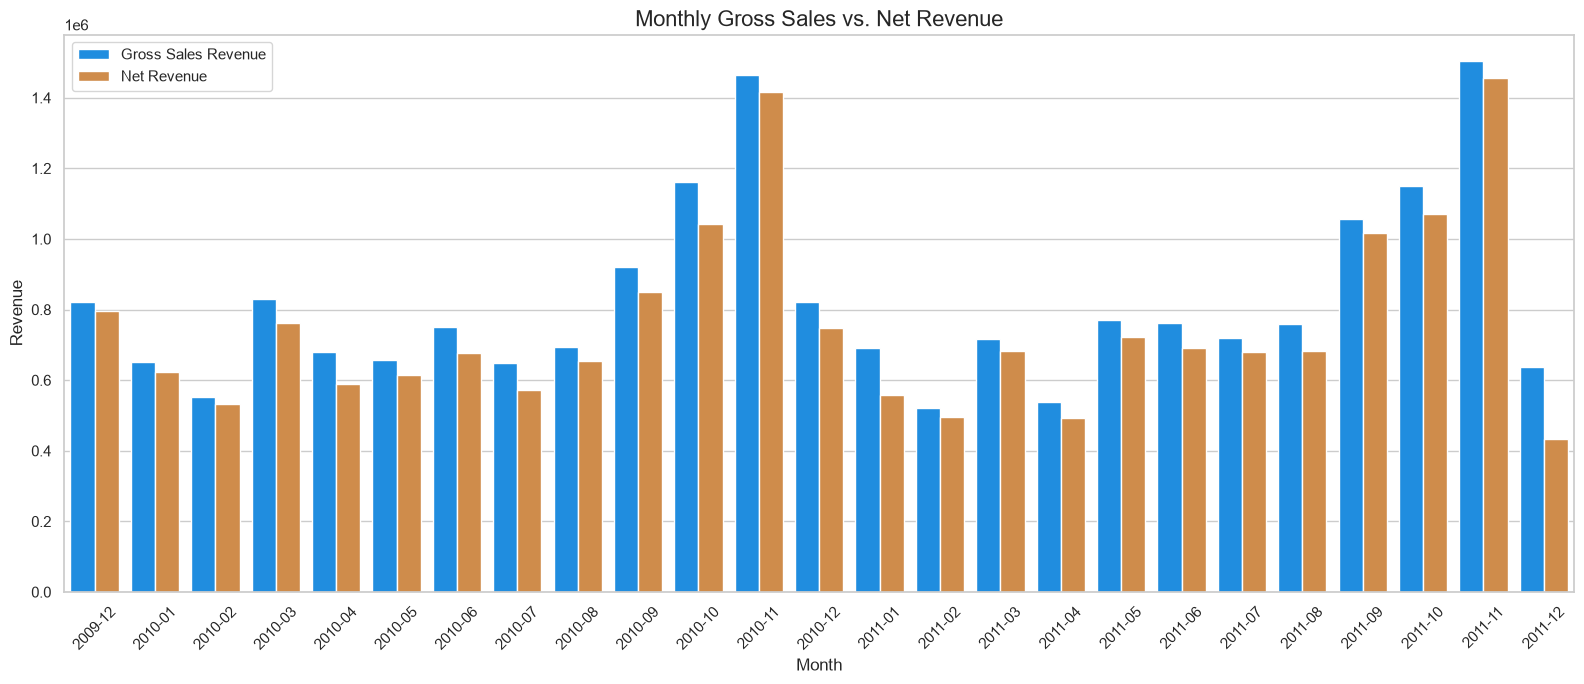

In [163]:
import seaborn as sns
import matplotlib.pyplot as plt


plot_data = monthly_summary.reset_index()

plot_data = plot_data.melt(
    id_vars="InvoiceDate",
    value_vars=["Gross Sales Revenue", "Net Revenue"],
    var_name="Revenue Type",
    value_name="Revenue"
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(16, 7))

sns.barplot(
    data=plot_data,
    x="InvoiceDate",
    y="Revenue",
    hue="Revenue Type",
    palette=["#0091FF", "#E58B35"]
)

plt.title("Monthly Gross Sales vs. Net Revenue", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend(title="")
plt.tight_layout()

from pathlib import Path

images_dir = Path.cwd() / "images"
images_dir.mkdir(exist_ok=True)

plt.savefig(
    images_dir / "monthly_sales_trends.png",
    dpi=150,
    bbox_inches="tight"
)



plt.show()



In [91]:
# Summarize rows with positive quantities and negative prices.
df.loc[
    (df["Quantity"] > 0) & (df["Price"] < 0),
    ["Quantity", "Price", "Revenue"]
].agg(["count", "sum", "min", "max"])

,Quantity,Price,Revenue
count,5,5.00,5.00
sum,5,-158676.14,-158676.14
min,1,-53594.36,-53594.36
max,1,-11062.06,-11062.06


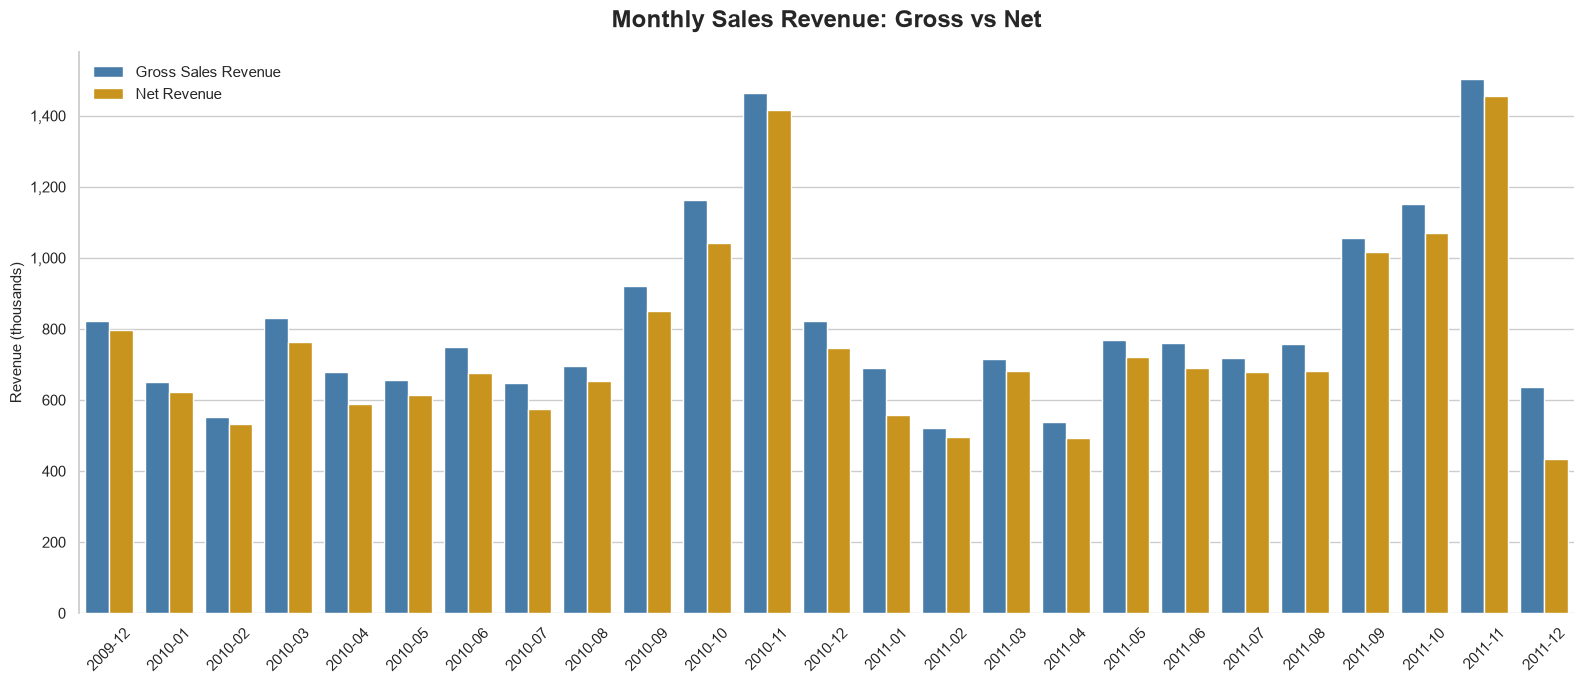

In [166]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plot_data = monthly_summary.reset_index().melt(
    id_vars="InvoiceDate",
    value_vars=["Gross Sales Revenue", "Net Revenue"],
    var_name="Revenue Type",
    value_name="Revenue"
)

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(16, 7))

sns.barplot(
    data=plot_data,
    x="InvoiceDate",
    y="Revenue",
    hue="Revenue Type",
    hue_order=["Gross Sales Revenue", "Net Revenue"],
    palette=["#377EB8", "#E69F00"],
    ax=ax
)

ax.set_title(
    "Monthly Sales Revenue: Gross vs Net",
    fontsize=17,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("")
ax.set_ylabel("Revenue (thousands)", fontsize=11)

# Display values in thousands.

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:,.0f}")
)

ax.tick_params(axis="x", rotation=45)
ax.legend(title="", frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax, left=False, bottom=True)

plt.tight_layout()


plt.savefig(
    images_dir / "Monthly_Gross_vs_Net.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [93]:
monthly_summary.reset_index().dtypes

InvoiceDate            period[M]
Gross Sales Revenue      float64
Negative Operations      float64
Net Revenue              float64
dtype: object

In [94]:


monthly_plot = monthly_summary.reset_index()

monthly_plot["InvoiceDate"] = (
    monthly_plot["InvoiceDate"].dt.to_timestamp()
)

monthly_plot.dtypes

InvoiceDate            datetime64[us]
Gross Sales Revenue           float64
Negative Operations           float64
Net Revenue                   float64
dtype: object

## Monthly Net Revenue Trend

This chart tracks monthly net revenue from December 2009 through December 2011. December 2011 is a partial month: the data end on December 9, so its total is not directly comparable with full months.

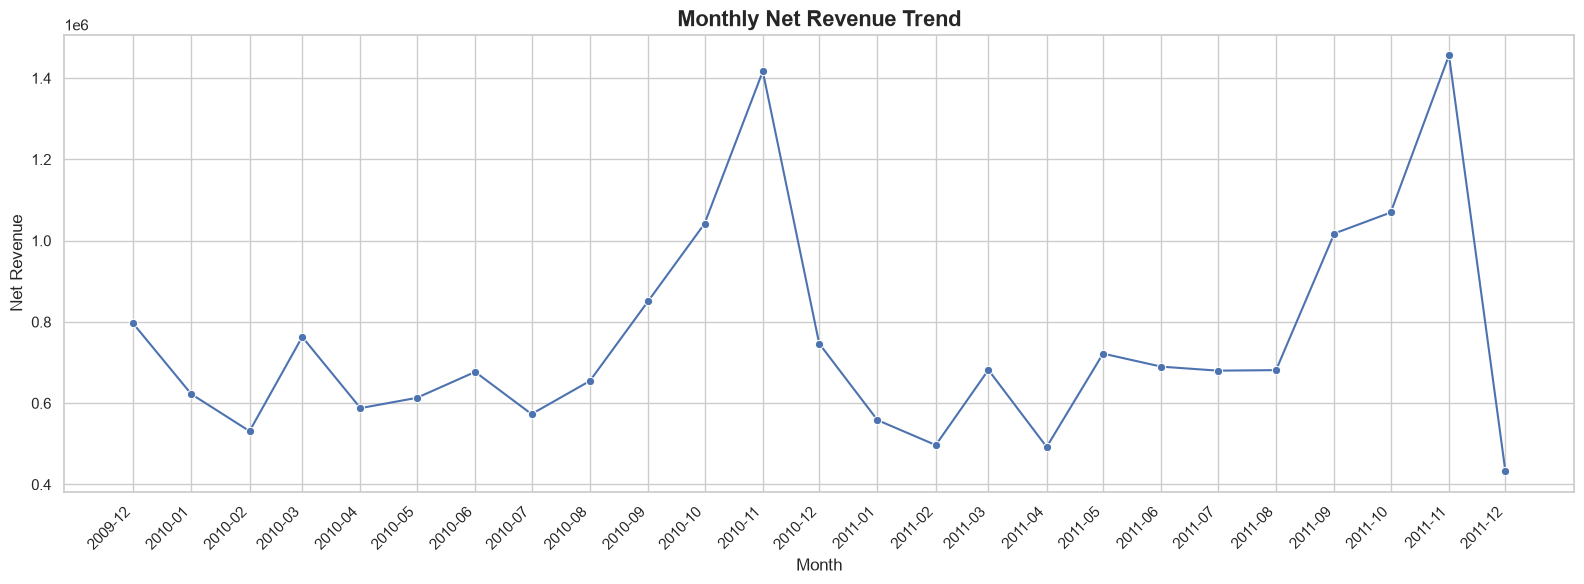

In [167]:
# Show a label for each month on the x-axis.

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_plot,
    x="InvoiceDate",
    y="Net Revenue",
    marker="o"
)

plt.title("Monthly Net Revenue Trend", fontsize=16, weight="bold")
plt.xlabel("Month")
plt.ylabel("Net Revenue")

# Format each month label as YYYY-MM.

plt.xticks(
    monthly_plot["InvoiceDate"],
    monthly_plot["InvoiceDate"].dt.strftime("%Y-%m"),
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    images_dir / "Monthly_Net_Revenue_Trend.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Top Months by Net Revenue

The table and chart below identify the five months with the highest net revenue in the dataset.

In [96]:
# Sort months by net revenue to identify the highest-revenue months.

monthly_summary.sort_values(
    by="Net Revenue",
    ascending=False
).head(5).round(2)

,Gross Sales Revenue,Negative Operations,Net Revenue
InvoiceDate,,,
2011-11,1503866.78,-47720.98,1456145.80
2010-11,1464293.14,-47595.94,1416697.20
2011-10,1151263.73,-81895.50,1069368.23
2010-10,1161902.22,-81290.74,1041685.61
2011-09,1056435.19,-38838.51,1017596.68


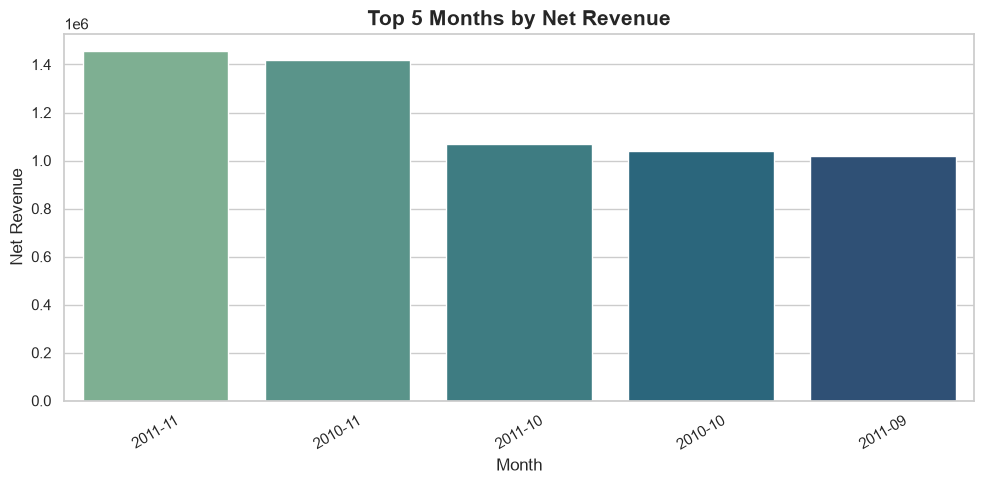

In [168]:
# Plot the five months with the highest net revenue.

top_5_months = (
    monthly_summary
    .nlargest(5, "Net Revenue")
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_5_months,
    x="InvoiceDate",
    y="Net Revenue",
    hue="InvoiceDate",
    palette="crest",
    legend=False
)

plt.title("Top 5 Months by Net Revenue", fontsize=15, weight="bold")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=30)
plt.tight_layout()


plt.savefig(
    images_dir / "top_5_revenue.png",
    dpi=150,
    bbox_inches="tight"
)


plt.show()

## Lowest-Revenue Months

This ranking includes all available data. The dataset covers partial months at its boundaries, so the values show recorded revenue for each available period and are not adjusted for the number of days observed.

In [98]:

# Find the five months with the lowest net revenue.
bottom_5_months = monthly_summary.sort_values(
    by="Net Revenue",
    ascending=True
).head(5)

bottom_5_months.round(2)


,Gross Sales Revenue,Negative Operations,Net Revenue
InvoiceDate,,,
2011-12,637808.33,-205089.27,432719.06
2011-04,536968.49,-44600.65,492367.84
2011-02,522545.56,-25519.15,497026.41
2010-02,551878.30,-20612.93,531265.37
2011-01,689811.61,-131363.05,558448.56


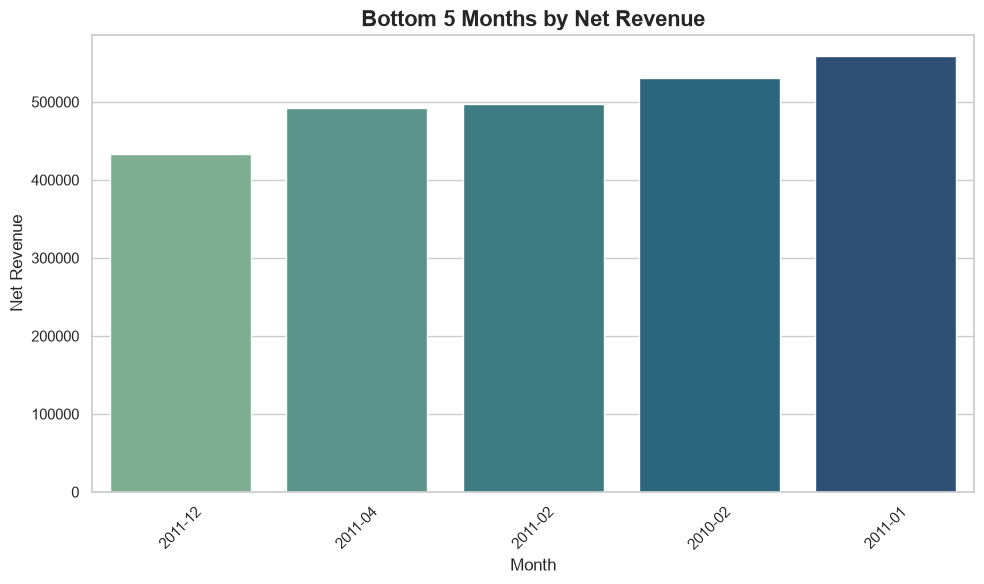

In [169]:

# Visualize the five months with the lowest net revenue.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=bottom_5_months.reset_index(),
    x="InvoiceDate",
    y="Net Revenue",
    hue="InvoiceDate",
    palette="crest",
    legend=False
)

plt.title("Bottom 5 Months by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    images_dir / "bottom_5_revenue.png",
    dpi=150,
    bbox_inches="tight"
)


plt.show()


## Revenue by Country

This section compares net revenue across countries. Net revenue is calculated as the sum of `Revenue` across all transaction rows.

In [100]:

# Calculate net revenue for each country.

country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 countries with the highest net revenue.

top_10_countries = country_revenue.head(10)

top_10_countries.round(2)


Country
United Kingdom    15986060.34
EIRE                609953.78
Netherlands         548330.70
Germany             411959.16
France              321733.39
Australia           166444.42
Switzerland          99403.06
Spain                91013.44
Sweden               87775.52
Denmark              64459.59
Name: Revenue, dtype: float64

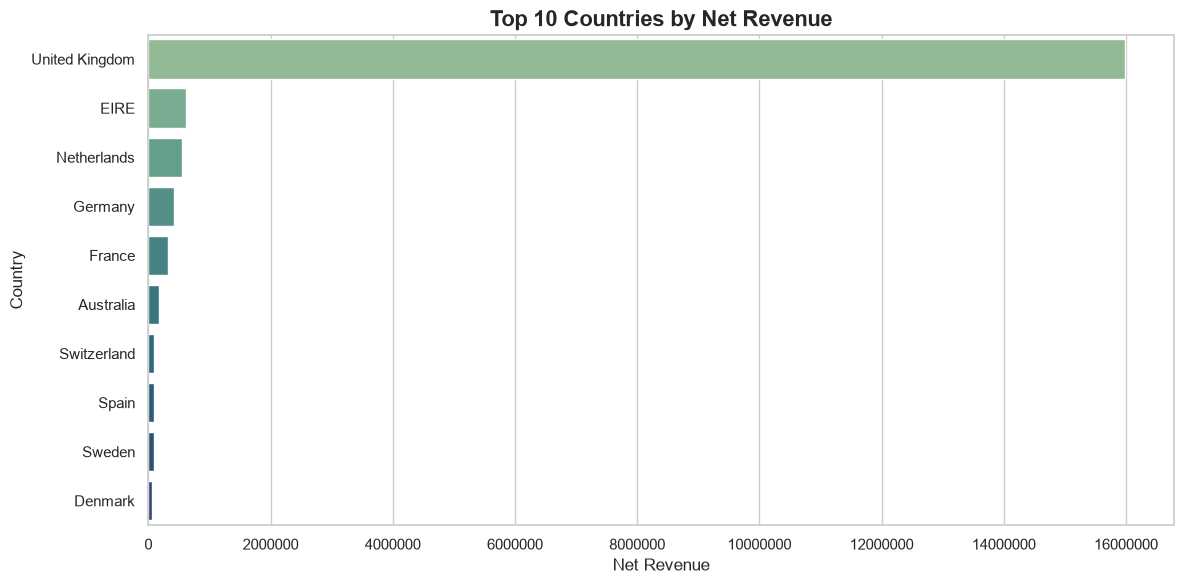

In [170]:

# Visualize the top 10 countries by net revenue.
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index,
    hue=top_10_countries.index,
    palette="crest",
    legend=False
)

plt.title("Top 10 Countries by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Net Revenue")
plt.ylabel("Country")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()

plt.savefig(
    images_dir / "top_10_countries",
    dpi=150,
    bbox_inches="tight"
)



plt.show()


## Unique Invoices by Country

This analysis counts distinct invoice numbers for each country. It includes invoice numbers starting with `C`, so the counts may include cancellation invoices and should not be interpreted as completed sales orders.

In [102]:
# Count unique invoice numbers for each country.

country_orders = (
    df.groupby("Country")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
)
# Select the 10 countries with the most unique invoice numbers.

top_10_orders = country_orders.head(10)

top_10_orders


Country
United Kingdom    49108
Germany            1095
EIRE                806
France              746
Netherlands         250
Spain               188
Belgium             183
Sweden              129
Portugal            124
Switzerland         123
Name: Invoice, dtype: int64

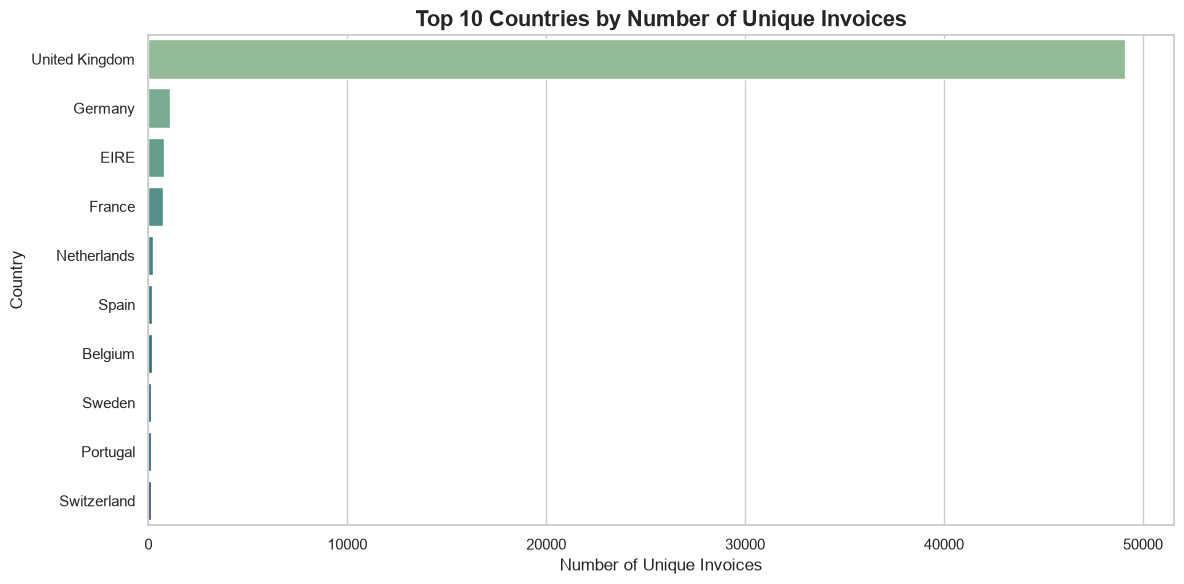

In [171]:

# Visualize the top 10 countries by number of unique invoices.

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_orders.values,
    y=top_10_orders.index,
    hue=top_10_orders.index,
    palette="crest",
    legend=False
)

plt.title("Top 10 Countries by Number of Unique Invoices", fontsize=16, weight="bold")
plt.xlabel("Number of Unique Invoices")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(
    images_dir / "top_10_countries_invoices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## Net Revenue by Stock Code

This analysis ranks stock codes by net revenue. The ranking may include charges such as postage, as well as merchandise.

In [104]:
# Calculate net revenue for each product.
product_revenue = (
    df.groupby(["StockCode", "Description"], dropna=False)["Revenue"]
    .sum()
    .reset_index(name="Net Revenue")
    .sort_values("Net Revenue", ascending=False)
)

# Select the 10 products with the highest net revenue.

top_10_products = product_revenue.head(10)

top_10_products.round(2)


,StockCode,Description,Net Revenue
3138,22423,REGENCY CAKESTAND 3 TIER,314045.02
8990,DOT,DOTCOM POSTAGE,309844.10
8070,85123A,WHITE HANGING HEART T-LIGHT HOLDER,248159.10
5703,47566,PARTY BUNTING,147079.73
8015,85099B,JUMBO BAG RED RETROSPOT,143834.41
7454,84879,ASSORTED COLOUR BIRD ORNAMENT,128550.42
2592,22086,PAPER CHAIN KIT 50'S CHRISTMAS,116298.59
8995,POST,POSTAGE,110430.41
6353,79321,CHILLI LIGHTS,79905.13
6687,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,70969.95


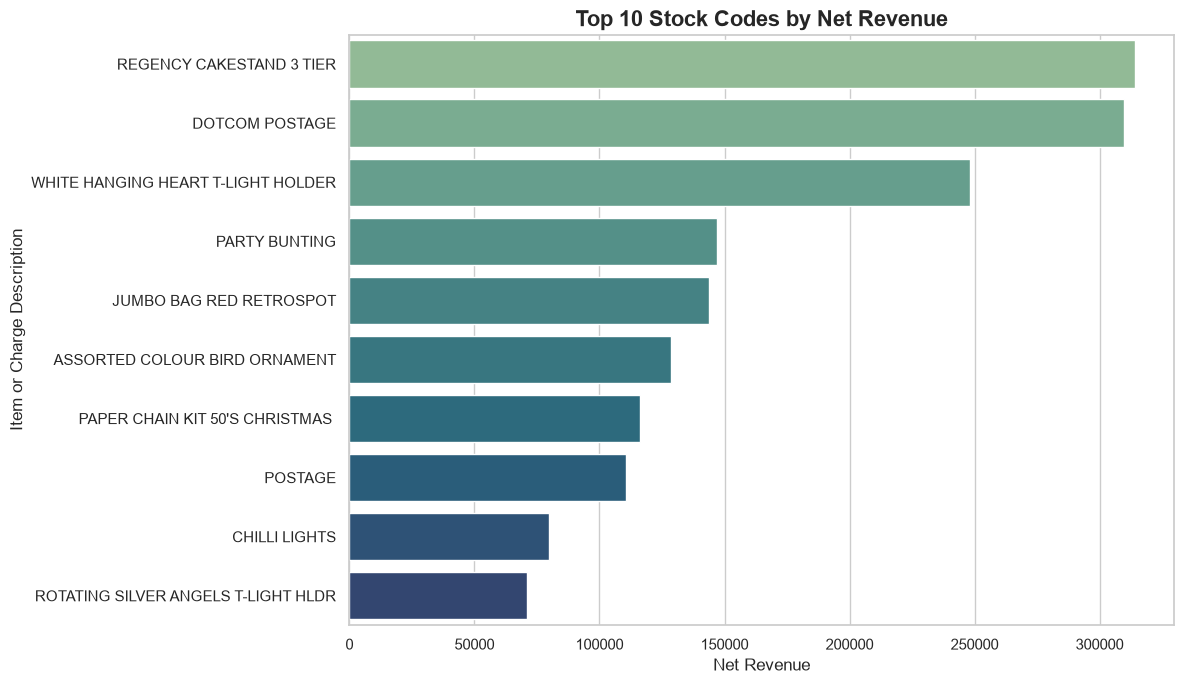

In [172]:
# Visualize the top 10 stock codes by net revenue.

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_products,
    x="Net Revenue",
    y="Description",
    hue="Description",
    palette="crest",
    legend=False
)

plt.title("Top 10 Stock Codes by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Net Revenue")
plt.ylabel("Item or Charge Description")
plt.tight_layout()
plt.savefig(
    images_dir / "top_10_Code_net_rev.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [106]:
# Count unique sales invoices for the top-revenue stock codes.
top_product_keys = top_10_products[
    ["StockCode", "Description"]
].drop_duplicates()

top_products_orders = (
    sales.merge(
        top_product_keys,
        on=["StockCode", "Description"],
        how="inner"
    )
    .groupby(["StockCode", "Description"])["Invoice"]
    .nunique()
    .sort_values(ascending=False)
)

top_products_orders

StockCode  Description                        
85123A     WHITE HANGING HEART T-LIGHT HOLDER     5356
22423      REGENCY CAKESTAND 3 TIER               3918
85099B     JUMBO BAG RED RETROSPOT                3245
84879      ASSORTED COLOUR BIRD ORNAMENT          2807
47566      PARTY BUNTING                          2674
22086      PAPER CHAIN KIT 50'S CHRISTMAS         2018
POST       POSTAGE                                1851
DOT        DOTCOM POSTAGE                         1415
79321      CHILLI LIGHTS                          1135
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     756
Name: Invoice, dtype: int64

In [107]:
# Inspect examples of DOTCOM POSTAGE transactions.

sales.loc[
    sales["Description"] == "DOTCOM POSTAGE",
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "Revenue", "Country"]
].head(10)

,Invoice,StockCode,Description,Quantity,Price,Revenue,Country
2379,489597,DOT,DOTCOM POSTAGE,1,647.19,647.19,United Kingdom
2539,489600,DOT,DOTCOM POSTAGE,1,55.96,55.96,United Kingdom
2551,489601,DOT,DOTCOM POSTAGE,1,68.39,68.39,United Kingdom
2571,489602,DOT,DOTCOM POSTAGE,1,59.35,59.35,United Kingdom
2619,489603,DOT,DOTCOM POSTAGE,1,42.39,42.39,United Kingdom
2644,489604,DOT,DOTCOM POSTAGE,1,50.87,50.87,United Kingdom
2686,489607,DOT,DOTCOM POSTAGE,1,76.30,76.30,United Kingdom
2698,489609,DOT,DOTCOM POSTAGE,1,74.61,74.61,United Kingdom
2771,489612,DOT,DOTCOM POSTAGE,1,87.39,87.39,United Kingdom
2806,489614,DOT,DOTCOM POSTAGE,1,80.30,80.30,United Kingdom


In [108]:
# Inspect the line items in three selected invoices.
selected_invoices = ["489597", "489600", "489601"]

sales.loc[
    sales["Invoice"].isin(selected_invoices),
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "Revenue"]
].sort_values(["Invoice", "Description"])

,Invoice,StockCode,Description,Quantity,Price,Revenue
2156,489597,22150,3 STRIPEY MICE FELTCRAFT,2,4.30,8.60
2122,489597,22068,BLACK PIRATE TREASURE CHEST,1,3.43,3.43
2123,489597,22069,BROWN PIRATE TREASURE CHEST,1,3.43,3.43
1989,489597,21379,CAMPHOR WOOD PORTOBELLO MUSHROOM,1,2.57,2.57
1963,489597,21185,HOME SWEET HOME BLACKBOARD,2,13.00,26.00
...,...,...,...,...,...,...
2542,489601,22166,"WALL MIRROR , RECT DIAMANTE, PINK/",1,16.48,16.48
2555,489601,21192,WHITE BELL HONEYCOMB PAPER,1,3.43,3.43
2546,489601,71053,WHITE METAL LANTERN,1,8.65,8.65
2552,489601,18096c,WHITE ROUND PORCELAIN TLIGHT HOLDER,1,5.17,5.17


In [109]:
# Display the line items for one invoice.

sales.loc[
    sales["Invoice"] == "489597",
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "Revenue"]
].sort_values("Description")

,Invoice,StockCode,Description,Quantity,Price,Revenue
2156,489597,22150,3 STRIPEY MICE FELTCRAFT,2,4.30,8.60
2122,489597,22068,BLACK PIRATE TREASURE CHEST,1,3.43,3.43
2123,489597,22069,BROWN PIRATE TREASURE CHEST,1,3.43,3.43
1989,489597,21379,CAMPHOR WOOD PORTOBELLO MUSHROOM,1,2.57,2.57
1963,489597,21185,HOME SWEET HOME BLACKBOARD,2,13.00,26.00
...,...,...,...,...,...,...
1894,489597,20719,WOODLAND CHARLOTTE BAG,1,1.70,1.70
2014,489597,21542,WOODLAND WATER TRANSFER TATTOOS,1,1.70,1.70
2217,489597,37444A,YELLOW BREAKFAST CUP AND SAUCER,3,6.04,18.12
2344,489597,85136A,YELLOW SHARK HELICOPTER,2,8.65,17.30


In [110]:
# Review the line items in the three selected invoices.

selected_invoices = ["489597", "489600", "489601"]

invoice_details = (
    sales.loc[
        sales["Invoice"].isin(selected_invoices),
        ["Invoice", "StockCode", "Description", "Quantity", "Price", "Revenue"]
    ]
    .sort_values(["Invoice", "Description"])
)

# Limit the displayed output to a manageable number of rows.

with pd.option_context("display.max_rows", None):
    display(invoice_details.head(20))

,Invoice,StockCode,Description,Quantity,Price,Revenue
2156,489597,22150,3 STRIPEY MICE FELTCRAFT,2,4.30,8.60
2122,489597,22068,BLACK PIRATE TREASURE CHEST,1,3.43,3.43
2123,489597,22069,BROWN PIRATE TREASURE CHEST,1,3.43,3.43
1989,489597,21379,CAMPHOR WOOD PORTOBELLO MUSHROOM,1,2.57,2.57
1963,489597,21185,HOME SWEET HOME BLACKBOARD,2,13.00,26.00
2004,489597,21493,VINTAGE DESIGN GIFT TAGS,4,1.70,6.80
2258,489597,79323W,WHITE CHERRY LIGHTS,1,13.87,13.87
1898,489597,20739,*USB Office Glitter Lamp,1,8.65,8.65
2214,489597,35962,12 ASS ZINC CHRISTMAS DECORATIONS,1,4.30,4.30
1925,489597,20975,12 PENCILS SMALL TUBE RED SPOTTY,1,1.30,1.30


## Exploring Postage Charges

This fixed random sample of 10 sales invoices is used to inspect whether DOTCOM POSTAGE appears alongside merchandise. The sample is illustrative and does not show how common postage charges are across all invoices.

In [111]:
# Check whether DOTCOM POSTAGE appears in sampled invoices.

valid_sales = sales.loc[
    (sales["Quantity"] > 0) &
    (sales["Price"] > 0)
]

# Select 10 random sales invoices.
random_invoices = (
    valid_sales["Invoice"]
    .drop_duplicates()
    .sample(n=10, random_state=42)
)

# Check whether each sampled invoice includes DOTCOM POSTAGE.
dot_check = (
    sales[sales["Invoice"].isin(random_invoices)]
    .assign(
        has_dot=lambda x: x["Description"].eq("DOTCOM POSTAGE")
    )
    .groupby("Invoice")
    .agg(
        total_positions=("StockCode", "size"),
        has_dot=("has_dot", "any")
    )
)

dot_check

,total_positions,has_dot
Invoice,,
490962,4,False
493443,47,False
507166,15,False
535394,12,False
539033,1,False
553462,28,False
555003,8,False
557100,3,False
578353,7,False


## Lowest Net Revenue by Stock Code

This section ranks stock codes by total net revenue across all transaction rows. Net revenue sums `Revenue`, including negative transactions, so some values may be negative. The ranking may include charges such as postage, as well as merchandise.

In [112]:
# Find the 10 stock codes with the lowest net revenue.

bottom_10_products = (
    sales.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=True)
    .head(10)
    .reset_index()
)

bottom_10_products.round(2)

,StockCode,Description,Revenue
0,PADS,PADS TO MATCH ALL CUSHIONS,0.02
1,84205C,HAPPY BIRTHDAY GINGER CAT CARD,0.38
2,35930,PINK HEART CHRISTMAS DECORATION,0.38
3,23366,SET 12 COLOURING PENCILS DOILEY,0.65
4,84206B,CAT W SUNGLASSES BLANK CARD,0.76
5,51014c,"FEATHER PEN,COAL BLACK",0.83
6,20721,OWLS CHARLOTTE BAG,0.85
7,84206B,CAT WITH SUNGLASSES BLANK CARD,0.95
8,TEST002,This is a test product.,1.00
9,35976B,WHITE SCANDINAVIAN HEART CHRISTMAS,1.25


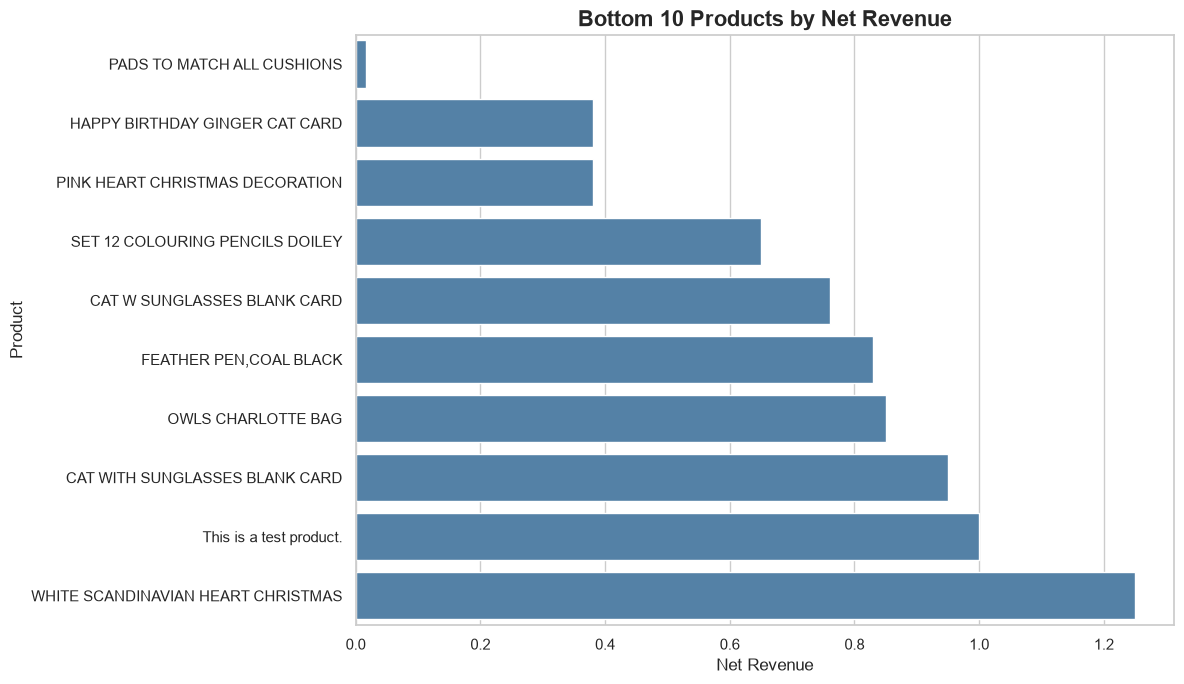

In [173]:
# 10 stock codes with the lowest net revenue

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(12, 7))

sns.barplot(
    data=bottom_10_products,
    x="Revenue",
    y="Description",
    color="steelblue"
)

plt.title("Bottom 10 Products by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Net Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    images_dir / "bottom_10_prod_Net_rev.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [114]:
# Calculate sales and order counts for the 10 products with the lowest revenue.
bottom_10_sales = (
    sales[sales["StockCode"].isin(bottom_10_products["StockCode"])]
    .groupby(["StockCode", "Description"])
    .agg(
        Units_Sold=("Quantity", "sum"),
        Number_of_Orders=("Invoice", "nunique"),
        Net_Revenue=("Revenue", "sum")
    )
    .sort_values("Net_Revenue")
)

bottom_10_sales.round(2)

,,Units_Sold,Number_of_Orders,Net_Revenue
StockCode,Description,,,
PADS,PADS TO MATCH ALL CUSHIONS,17,17,0.02
84205C,HAPPY BIRTHDAY GINGER CAT CARD,2,1,0.38
35930,PINK HEART CHRISTMAS DECORATION,1,1,0.38
23366,SET 12 COLOURING PENCILS DOILEY,1,1,0.65
84206B,CAT W SUNGLASSES BLANK CARD,4,1,0.76
51014c,"FEATHER PEN,COAL BLACK",1,1,0.83
20721,OWLS CHARLOTTE BAG,1,1,0.85
84206B,CAT WITH SUNGLASSES BLANK CARD,5,1,0.95
TEST002,This is a test product.,1,1,1.00


In [115]:
# Check for different descriptions among products in the bottom 10.
sales[
    sales["StockCode"].isin(bottom_10_products["StockCode"])
].groupby("StockCode")["Description"].nunique().sort_values(ascending=False)

StockCode
23366      3
84206B     2
20721      1
35976B     1
35930      1
51014c     1
84205C     1
PADS       1
TEST002    1
Name: Description, dtype: int64

## Bottom Products by Net Revenue

This section summarizes sales, units sold, and distinct invoices for the selected low-revenue stock codes. Results are aggregated by stock code, so entries with the same code are combined even if their descriptions differ.

In [116]:
# Aggregate sales by stock code.
bottom_10_sales = (
    sales[sales["StockCode"].isin(bottom_10_products["StockCode"])]
    .groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        Units_Sold=("Quantity", "sum"),
        Number_of_Orders=("Invoice", "nunique"),
        Net_Revenue=("Revenue", "sum")
    )
    .sort_values("Net_Revenue")
)

bottom_10_sales.round(2)

,Description,Units_Sold,Number_of_Orders,Net_Revenue
StockCode,,,,
PADS,PADS TO MATCH ALL CUSHIONS,17,17,0.02
35930,PINK HEART CHRISTMAS DECORATION,1,1,0.38
84205C,HAPPY BIRTHDAY GINGER CAT CARD,2,1,0.38
51014c,"FEATHER PEN,COAL BLACK",1,1,0.83
20721,OWLS CHARLOTTE BAG,1,1,0.85
TEST002,This is a test product.,1,1,1.00
35976B,WHITE SCANDINAVIAN HEART CHRISTMAS,1,1,1.25
84206B,CAT W SUNGLASSES BLANK CARD,9,2,1.71
23366,SET 12 COLOURING PENCILS DOILY,2249,195,1667.95


This chart groups the selected low-revenue items by stock code. Items with the same stock code are combined, so it shows nine stock codes rather than ten code-description pairs.

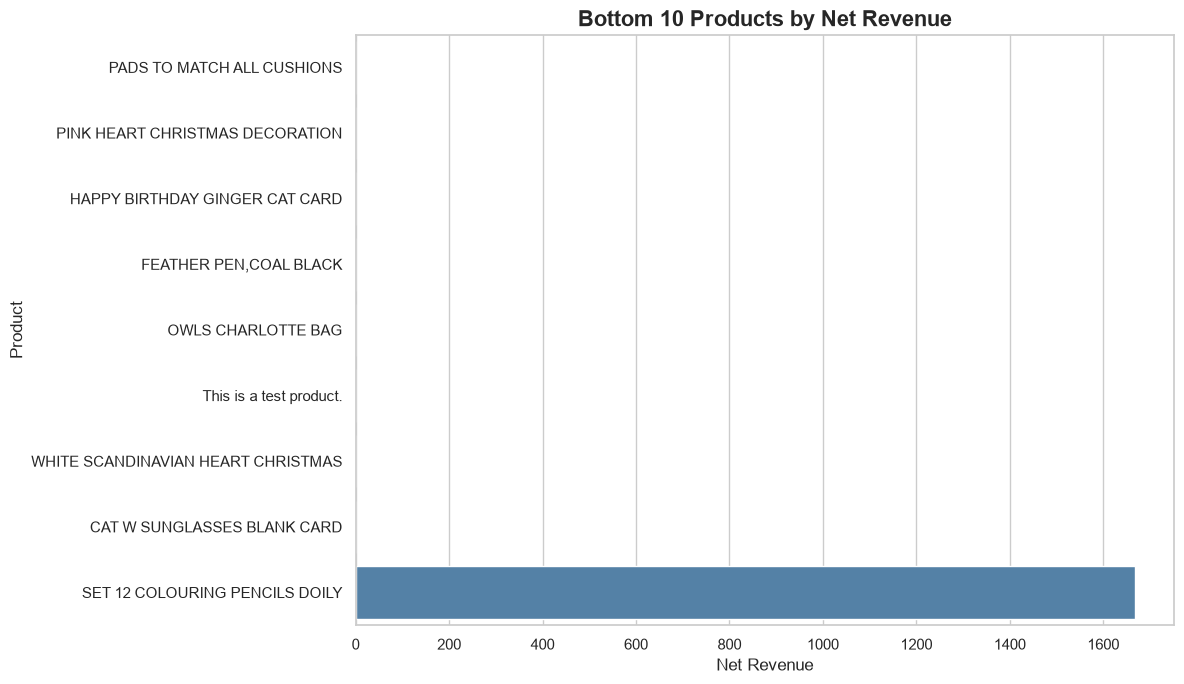

In [174]:
# Visualize the 10 products with the lowest net revenue.

plt.figure(figsize=(12, 7))

sns.barplot(
    data=bottom_10_sales.reset_index(),
    x="Net_Revenue",
    y="Description",
    color="steelblue"
)

plt.title("Bottom 10 Products by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Net Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    images_dir / "bpttom_10_prod_by_net_rev.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

This chart treats each stock code and description combination separately. Different descriptions with the same stock code appear as separate bars.

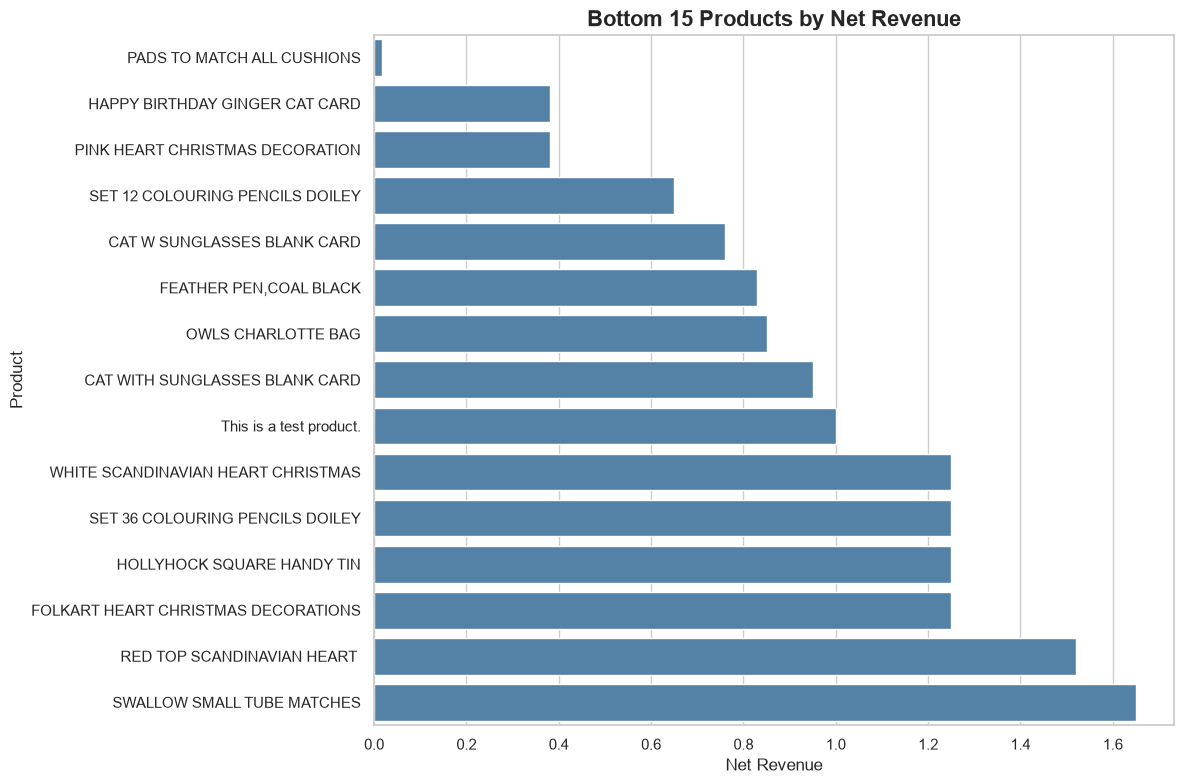

In [175]:
# Select the 15 products with the lowest net revenue.
bottom_15_products = (
    sales.groupby(["StockCode", "Description"], dropna=False)
    ["Revenue"]
    .sum()
    .sort_values()
    .head(15)
    .reset_index(name="Net_Revenue")
)

# Build the chart.
plt.figure(figsize=(12, 8))

sns.barplot(
    data=bottom_15_products,
    x="Net_Revenue",
    y="Description",
    color="steelblue"
)

plt.title("Bottom 15 Products by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Net Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    images_dir / "bot_15_prod_rev.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [119]:
# Calculate revenue for each stock code.

product_revenue = (
    sales.groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        Net_Revenue=("Revenue", "sum")
    )
    .sort_values("Net_Revenue")
)

# Display the 15 products with the lowest revenue.

bottom_15_products = product_revenue.head(15)

bottom_15_products.round(2)

,Description,Net_Revenue
StockCode,,
PADS,PADS TO MATCH ALL CUSHIONS,0.02
84205C,HAPPY BIRTHDAY GINGER CAT CARD,0.38
35930,PINK HEART CHRISTMAS DECORATION,0.38
51014c,"FEATHER PEN,COAL BLACK",0.83
20721,OWLS CHARLOTTE BAG,0.85
TEST002,This is a test product.,1.00
84845A,HOLLYHOCK SQUARE HANDY TIN,1.25
35976B,WHITE SCANDINAVIAN HEART CHRISTMAS,1.25
35950,FOLKART HEART CHRISTMAS DECORATIONS,1.25


This chart ranks stock codes by revenue summed across rows in `sales`. Each stock code is shown once, with its first associated description. Since `sales` contains positive-sale rows, the values represent revenue from those rows rather than net revenue across all transactions.

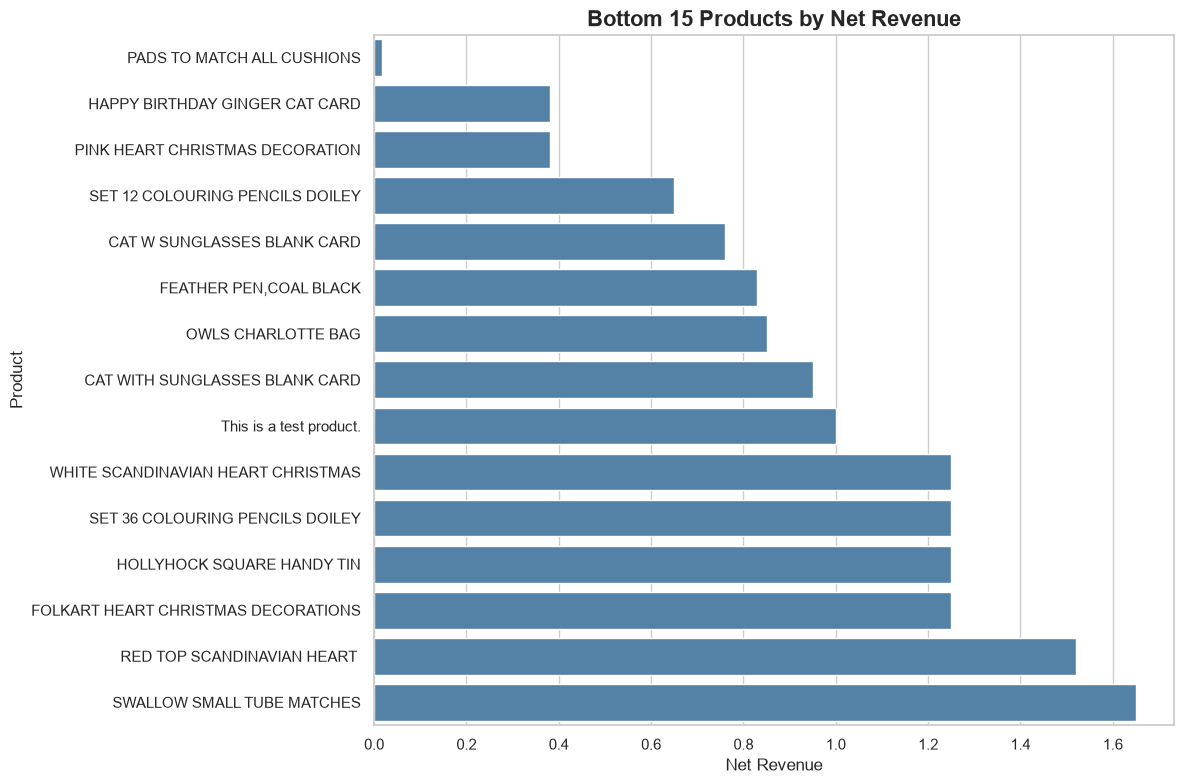

In [176]:
# Visualize the 15 products with the lowest net revenue. 
plt.figure(figsize=(12, 8))

sns.barplot(
    data=bottom_15_products.reset_index(),
    x="Net_Revenue",
    y="Description",
    color="steelblue"
)

plt.title("Bottom 15 Products by Net Revenue", fontsize=16, weight="bold")
plt.xlabel("Net Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    images_dir / "bot_15_prod_by_net_rev.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Top Products by Units Sold

This section ranks products by total quantity in the sales data. Products are grouped by stock code and description, and the number of distinct invoices is shown for context. One product has 80,995 units recorded on a single invoice; this extreme value strongly affects the ranking and should be interpreted with caution.

In [121]:

# Calculate sales and order counts for each product.
top_10_by_units = (
    sales.groupby(["StockCode", "Description"], as_index=False)
    .agg(
        Units_Sold=("Quantity", "sum"),
        Number_of_Orders=("Invoice", "nunique"),
        Net_Revenue=("Revenue", "sum")
    )
    .sort_values("Units_Sold", ascending=False)
    .head(10)
)

top_10_by_units.round(2)


,StockCode,Description,Units_Sold,Number_of_Orders,Net_Revenue
4171,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139,1019,24445.61
4999,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94142,5356,257546.20
3355,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.60
4640,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,2807,129324.49
2810,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,247,81700.92
4967,85099B,JUMBO BAG RED RETROSPOT,77280,3245,145961.83
121,17003,BROCADE RING PURSE,70369,456,14766.42
1384,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,1993,28081.73
4801,84991,60 TEATIME FAIRY CAKE CASES,54028,2127,27041.21
1607,22197,SMALL POPCORN HOLDER,48561,1407,42699.89


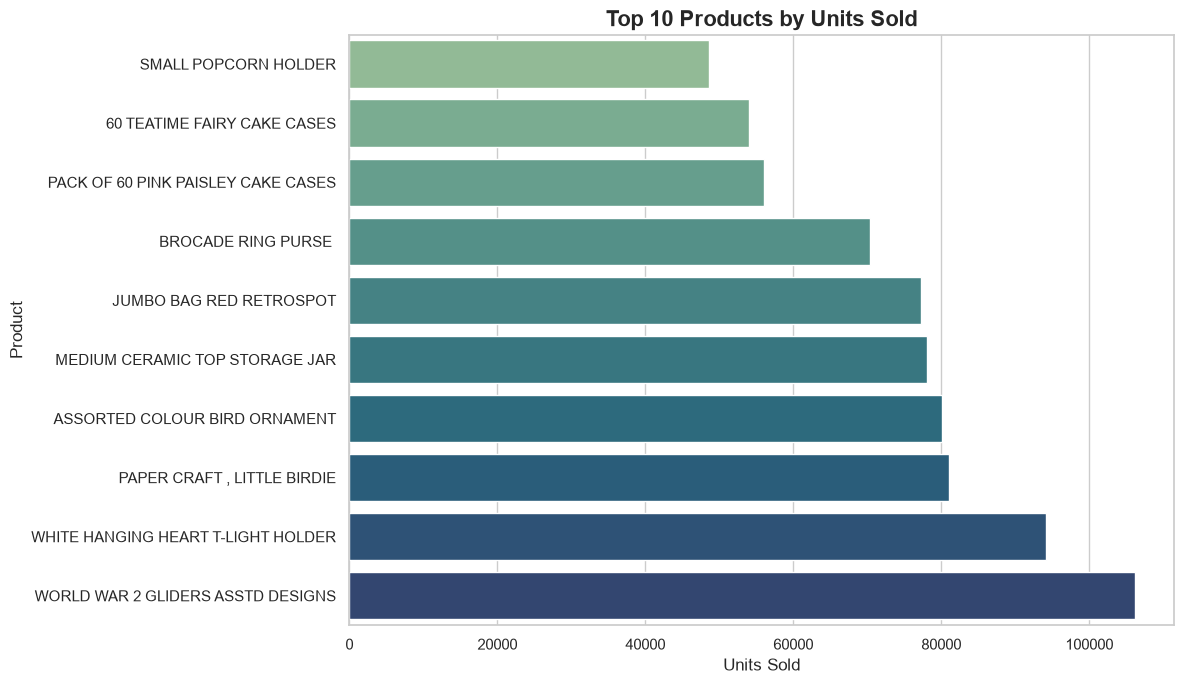

In [177]:
# Display the 10 products with the highest number of units sold.

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_by_units.sort_values("Units_Sold"),
    x="Units_Sold",
    y="Description",
    hue="Description",
    palette="crest",
    legend=False
)

plt.title("Top 10 Products by Units Sold", fontsize=16, weight="bold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    images_dir / "top_10_prod_unit_sold.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


### Units Sold and Revenue for Selected Products

This table summarizes units sold and revenue for the stock codes selected in the top 10 products analysis. It uses the `sales` subset, which includes rows with positive quantities and prices, and groups the results by stock code. Repeated stock codes are combined, so the table may contain fewer than 10 rows. These are sales totals, not net totals across all transaction types.

In [123]:
# Calculate net units sold for the top 10 products.

top_10_net_units = (
    sales[sales["StockCode"].isin(top_10_products["StockCode"])]
    .groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        Net_Units_Sold=("Quantity", "sum"),
        Net_Revenue=("Revenue", "sum")
    )
    .sort_values("Net_Units_Sold", ascending=False)
)

top_10_net_units.round(2)

,Description,Net_Units_Sold,Net_Revenue
StockCode,,,
85099B,JUMBO BAG RED WHITE SPOTTY,96757,180569.34
85123A,WHITE HANGING HEART T-LIGHT HOLDER,94203,257724.71
84879,ASSORTED COLOUR BIRD ORNAMENT,80082,129324.49
22086,PAPER CHAIN KIT 50'S CHRISTMAS,35084,117760.29
84347,ROTATING SILVER ANGELS T-LIGHT HLDR,31409,71300.40
47566,PARTY BUNTING,28200,148318.28
22423,REGENCY CAKESTAND 3 TIER,26478,330590.32
79321,CHILLI LIGHTS,15841,80540.88
POST,POSTAGE,5363,125682.42


In [124]:
# Display variables whose names are related to products.

[name for name in globals() if "product" in name.lower()]

['product_revenue',
 'top_10_products',
 'top_product_keys',
 'top_products_orders',
 'bottom_10_products',
 'bottom_15_products']

In [125]:
# Calculate total units sold and revenue for each product.

net_product_summary = (
    sales.groupby(["StockCode", "Description"])
    .agg(
        Net_Units_Sold=("Quantity", "sum"),
        Net_Revenue=("Revenue", "sum")
    )
    .reset_index()
)

# Display the 10 products with the highest total units sold.
top_10_net_units = (
    net_product_summary
    .sort_values("Net_Units_Sold", ascending=False)
    .head(10)
)

top_10_net_units.round(2)

,StockCode,Description,Net_Units_Sold,Net_Revenue
4171,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139,24445.61
4999,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94142,257546.20
3355,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
4640,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,129324.49
2810,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
4967,85099B,JUMBO BAG RED RETROSPOT,77280,145961.83
121,17003,BROCADE RING PURSE,70369,14766.42
1384,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,28081.73
4801,84991,60 TEATIME FAIRY CAKE CASES,54028,27041.21
1607,22197,SMALL POPCORN HOLDER,48561,42699.89


In [126]:
# Display the 10 products with the highest total units sold.
top_10_net_units[
    ["StockCode", "Description", "Net_Units_Sold", "Net_Revenue"]
].round(2)

,StockCode,Description,Net_Units_Sold,Net_Revenue
4171,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139,24445.61
4999,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94142,257546.20
3355,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
4640,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,129324.49
2810,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
4967,85099B,JUMBO BAG RED RETROSPOT,77280,145961.83
121,17003,BROCADE RING PURSE,70369,14766.42
1384,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,28081.73
4801,84991,60 TEATIME FAIRY CAKE CASES,54028,27041.21
1607,22197,SMALL POPCORN HOLDER,48561,42699.89


These charts compare the 10 products with the highest total units sold. The right chart shows revenue for those same products. The calculations use the `sales` subset, so revenue reflects positive sales rows rather than net revenue across all transactions.

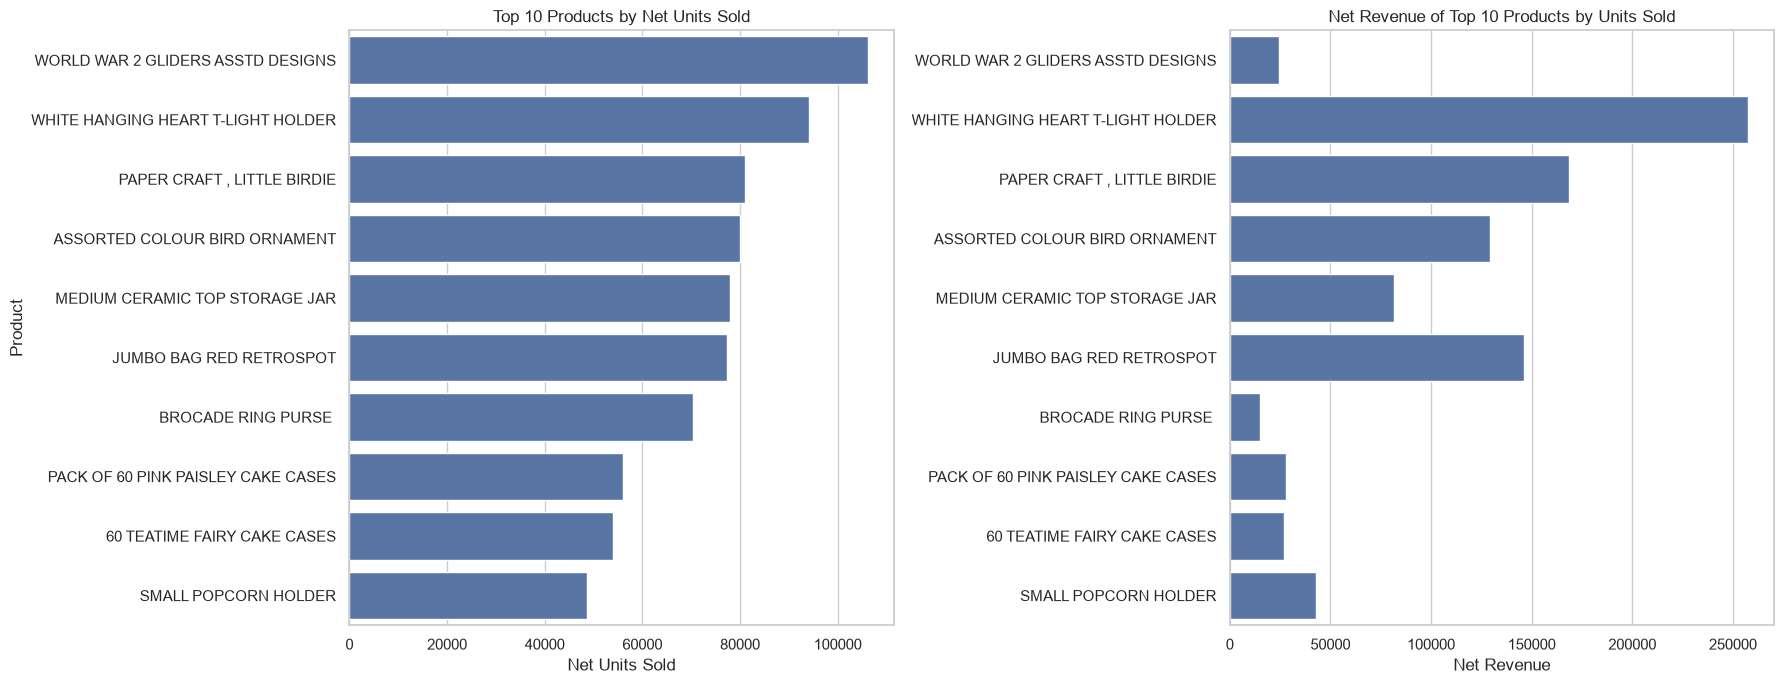

In [178]:
# Select the top 10 products by total units sold.

top_10_net_units = (
    net_product_summary
    .sort_values("Net_Units_Sold", ascending=False)
    .head(10)
)

# Plot two charts for the same products.

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=top_10_net_units,
    x="Net_Units_Sold",
    y="Description",
    ax=axes[0]
)
axes[0].set_title("Top 10 Products by Net Units Sold")
axes[0].set_xlabel("Net Units Sold")
axes[0].set_ylabel("Product")

sns.barplot(
    data=top_10_net_units,
    x="Net_Revenue",
    y="Description",
    ax=axes[1]
)
axes[1].set_title("Net Revenue of Top 10 Products by Units Sold")
axes[1].set_xlabel("Net Revenue")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(
    images_dir / "top_10_sold_vs_rev.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

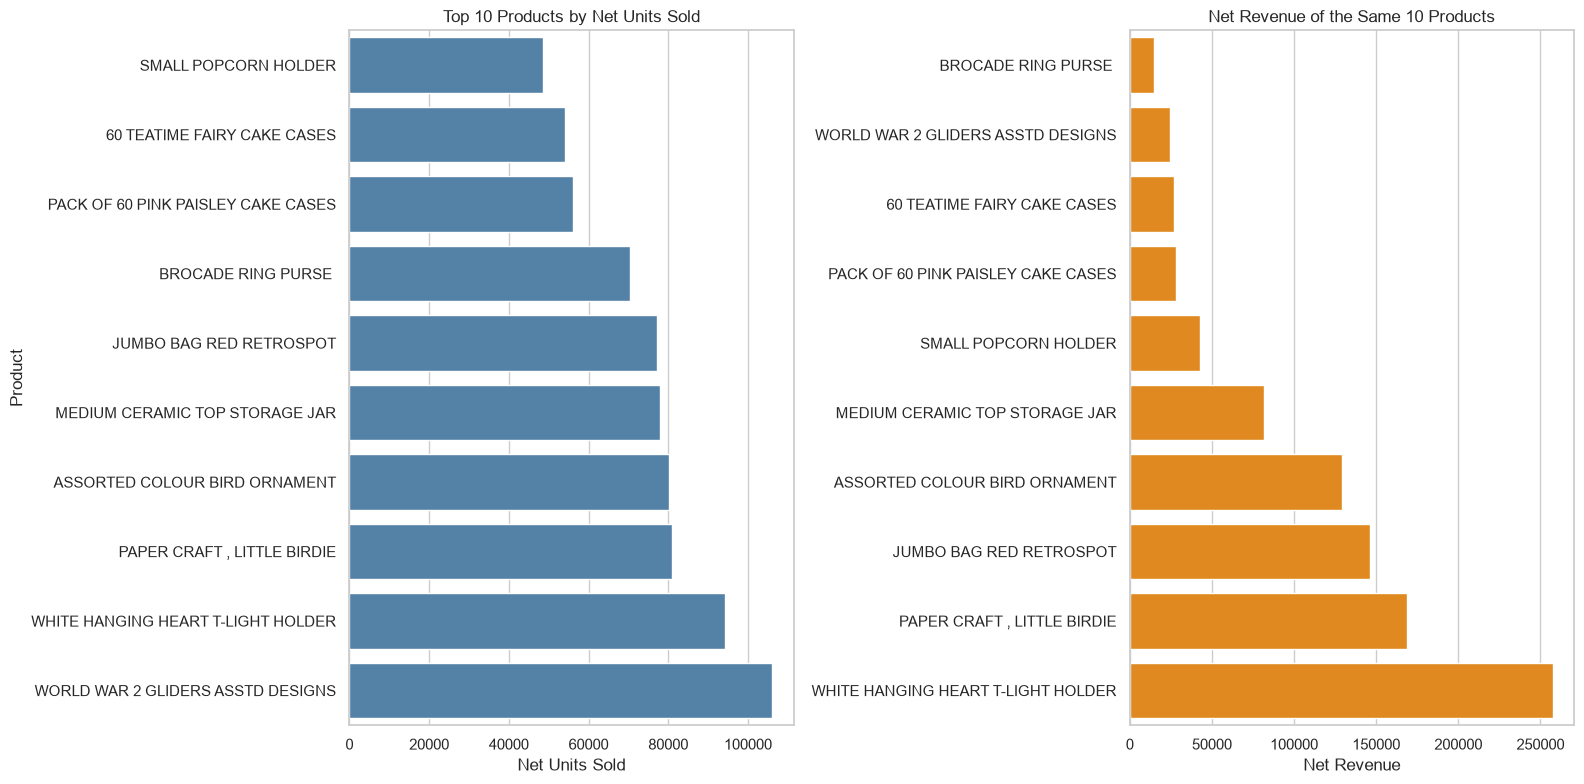

In [179]:

# Compare total units sold and revenue.

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Chart 1: total units sold.
sns.barplot(
    data=top_10_net_units.sort_values("Net_Units_Sold"),
    x="Net_Units_Sold",
    y="Description",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Top 10 Products by Net Units Sold")
axes[0].set_xlabel("Net Units Sold")
axes[0].set_ylabel("Product")

# Chart 2: revenue for the same products.
sns.barplot(
    data=top_10_net_units.sort_values("Net_Revenue"),
    x="Net_Revenue",
    y="Description",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Net Revenue of the Same 10 Products")
axes[1].set_xlabel("Net Revenue")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(
    images_dir / "top_10_prod_vs_rev_v2.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [129]:

# Validate and convert the invoice dates.
sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"],
    errors="coerce"
)

# Verify the conversion.
print("Data Type:", sales["InvoiceDate"].dtype)
print("First Date:", sales["InvoiceDate"].min())
print("Last Date:", sales["InvoiceDate"].max())
print("Number of dates that could not be parsed:",
      sales["InvoiceDate"].isna().sum())


Data Type: datetime64[us]
First Date: 2009-12-01 07:45:00
Last Date: 2011-12-09 12:50:00
Number of dates that could not be parsed: 0


## Monthly Sales Summary

This table summarizes revenue and units sold by month for rows in `sales`. Since `sales` contains positive-sale rows, these are sales totals rather than net values across all transactions. December 2009 and December 2011 are partial months; the figures include only the dates available in the dataset.

In [130]:
# Extract the month for each transaction.
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")

# Calculate monthly sales revenue and units sold.
monthly_sales = (
    sales.groupby("Month")
    .agg(
        Net_Revenue=("Revenue", "sum"),
        Net_Units_Sold=("Quantity", "sum")
    )
    .sort_index()
)

# Display the results.
monthly_sales.round(2)


,Net_Revenue,Net_Units_Sold
Month,,
2009-12,822483.95,425461
2010-01,651155.11,390672
2010-02,551878.30,381880
2010-03,830915.26,526026
2010-04,678875.25,366705
2010-05,657705.50,395868
2010-06,749537.31,406820
2010-07,648810.27,337895
2010-08,695251.91,472380


## Monthly Sales Trends

These charts show monthly revenue and units sold for rows in `sales`. Since `sales` includes only rows with positive quantities and prices, the figures represent positive sales rather than net totals across all transactions. December 2009 and December 2011 are partial months; values reflect only the dates available in the dataset.

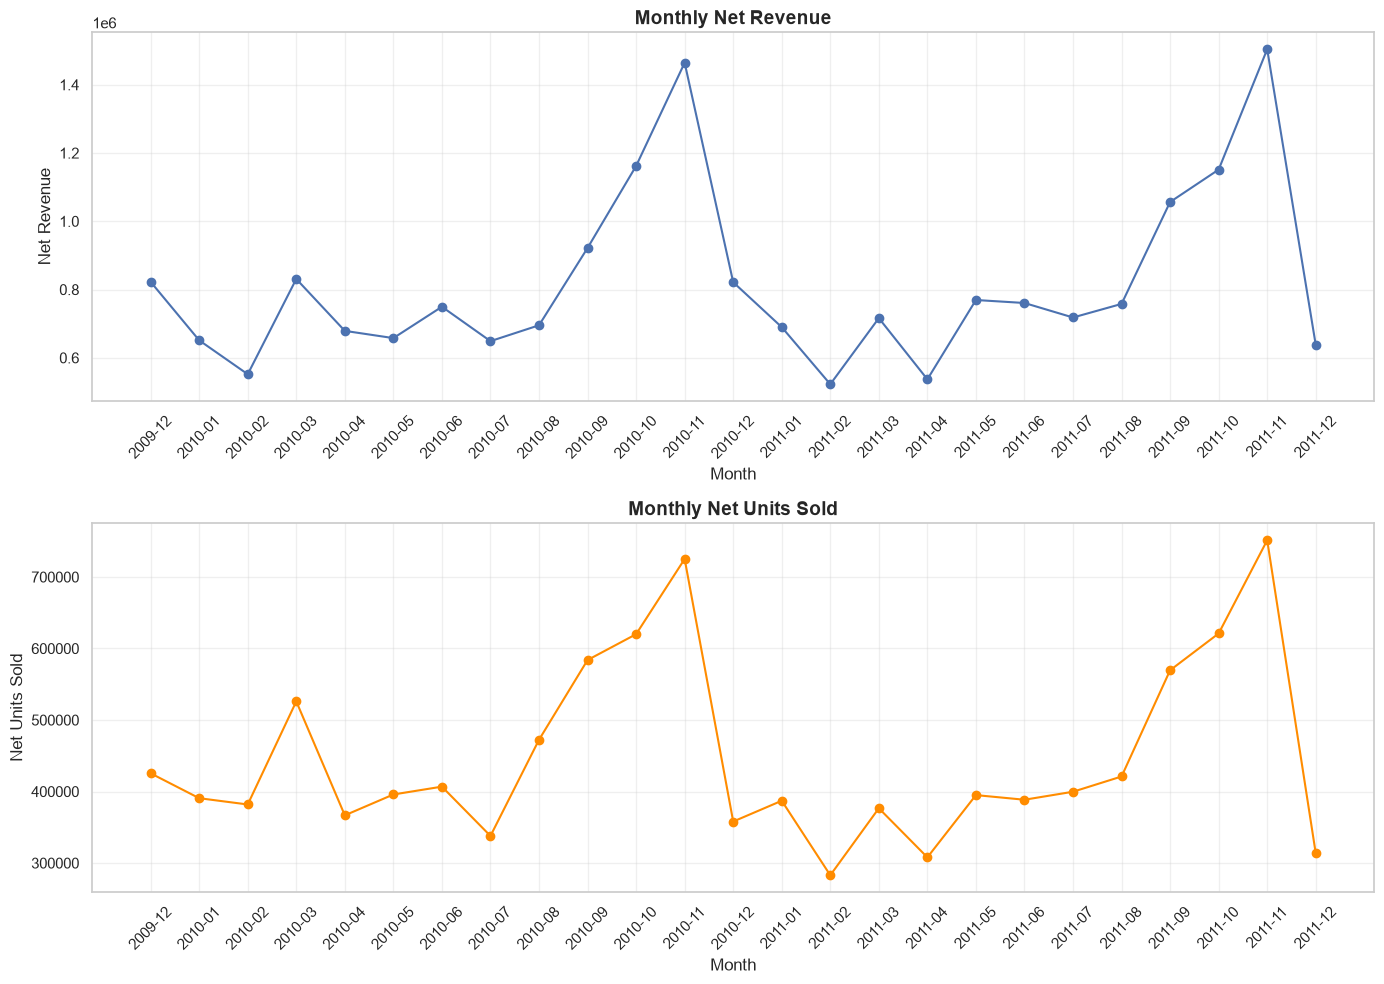

In [180]:

# Plot monthly sales trends in two charts.

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 1: monthly sales revenue.
axes[0].plot(
    monthly_sales.index.astype(str),
    monthly_sales["Net_Revenue"],
    marker="o"
)

axes[0].set_title("Monthly Net Revenue", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Net Revenue")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

# Chart 2: monthly units sold.
axes[1].plot(
    monthly_sales.index.astype(str),
    monthly_sales["Net_Units_Sold"],
    marker="o",
    color="darkorange"
)

axes[1].set_title("Monthly Net Units Sold", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Net Units Sold")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    images_dir / "monthly_sales_trends_vs_sold.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [132]:
# Calculate average sales revenue per unit sold.
monthly_sales["Revenue_per_Net_Unit"] = (
    monthly_sales["Net_Revenue"] /
    monthly_sales["Net_Units_Sold"]
)

monthly_sales[["Net_Revenue", "Net_Units_Sold", "Revenue_per_Net_Unit"]].round(2)

,Net_Revenue,Net_Units_Sold,Revenue_per_Net_Unit
Month,,,
2009-12,822483.95,425461,1.93
2010-01,651155.11,390672,1.67
2010-02,551878.30,381880,1.45
2010-03,830915.26,526026,1.58
2010-04,678875.25,366705,1.85
2010-05,657705.50,395868,1.66
2010-06,749537.31,406820,1.84
2010-07,648810.27,337895,1.92
2010-08,695251.91,472380,1.47


## Customer Purchase Frequency

This section counts distinct customer IDs in the positive-sales data; rows with missing customer IDs are excluded. It then counts distinct invoice numbers per customer as an indicator of purchase frequency. Invoice counts may not correspond exactly to completed orders.

In [133]:
# Count unique customers with recorded IDs.

unique_customers = sales["Customer ID"].nunique()

print(f"Number of unique customers: {unique_customers}")

Number of unique customers: 5878


In [134]:
# Count distinct invoices per customer.
customer_orders = (
    sales.groupby("Customer ID")["Invoice"]
    .nunique()
)

# Preview the first 10 customers.
customer_orders.head(10)

Customer ID
12346.0    12
12347.0     8
12348.0     5
12349.0     4
12350.0     1
12351.0     1
12352.0    10
12353.0     2
12354.0     1
12355.0     2
Name: Invoice, dtype: int64

In [135]:
# Count customers by number of invoices.
orders_distribution = customer_orders.value_counts().sort_index()

orders_distribution

Invoice
1      1623
2       944
3       664
4       486
5       360
       ... 
203       1
208       1
211       1
336       1
398       1
Name: count, Length: 90, dtype: int64

In [136]:
# Count customers with repeat purchases.

repeat_customers = (customer_orders > 1).sum()

# Calculate the share of repeat customers.

repeat_customer_share = repeat_customers / unique_customers * 100

print(f"Total unique customers: {unique_customers}")
print(f"Customers with repeat purchases: {repeat_customers}")
print(f"Repeat customer share: {repeat_customer_share:.2f}%")

Total unique customers: 5878
Customers with repeat purchases: 4255
Repeat customer share: 72.39%


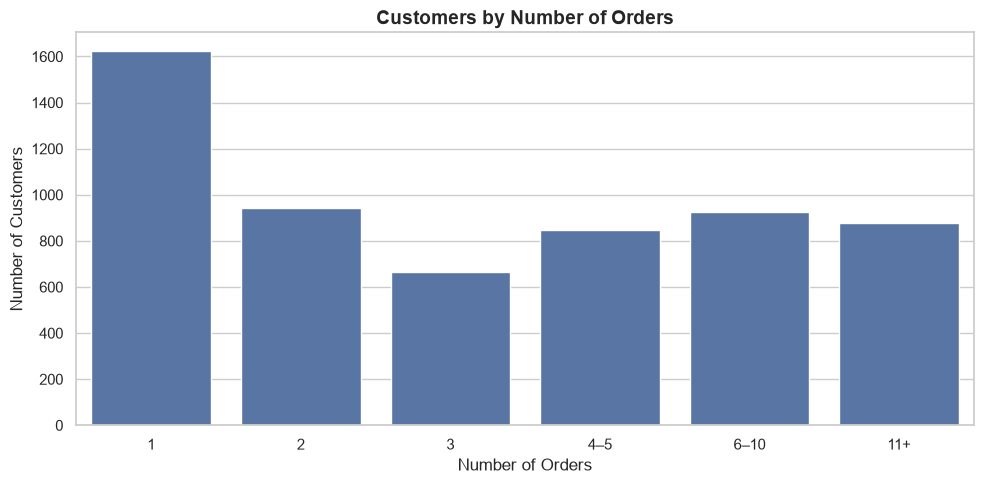

In [181]:
# Group customers by number of invoices.

order_groups = pd.cut(
    customer_orders,
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4–5", "6–10", "11+"]
)

order_group_counts = order_groups.value_counts().sort_index()

# Build the chart.
plt.figure(figsize=(10, 5))

sns.barplot(
    x=order_group_counts.index,
    y=order_group_counts.values
)

plt.title("Customers by Number of Orders", fontsize=14, fontweight="bold")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(
    images_dir / "customers_by_num_of_orders.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [138]:
print(sales.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue', 'Quantity_abs', 'Month']


## Invoice Value Analysis

Invoice revenue is calculated by summing `Revenue` for each invoice in the positive-sales subset. The mean invoice value (510.92) is higher than the median (302.22), suggesting that higher-value invoices pull the average upward. These are positive-sales totals, not net invoice values across all transaction rows.

In [139]:
# Calculate total revenue for each invoice.
order_revenue = sales.groupby("Invoice")["Revenue"].sum()

# Calculate the mean and median invoice value.
average_check = order_revenue.mean()
median_check = order_revenue.median()

print(f"average: {average_check:.2f}")
print(f"median: {median_check:.2f}")

average: 510.92
median: 302.22


In [140]:
# Check for negative and zero revenue.
print("negative Revenue:", (sales["Revenue"] < 0).sum())
print("Zero Revenue:", (sales["Revenue"] == 0).sum())

negative Revenue: 0
Zero Revenue: 0


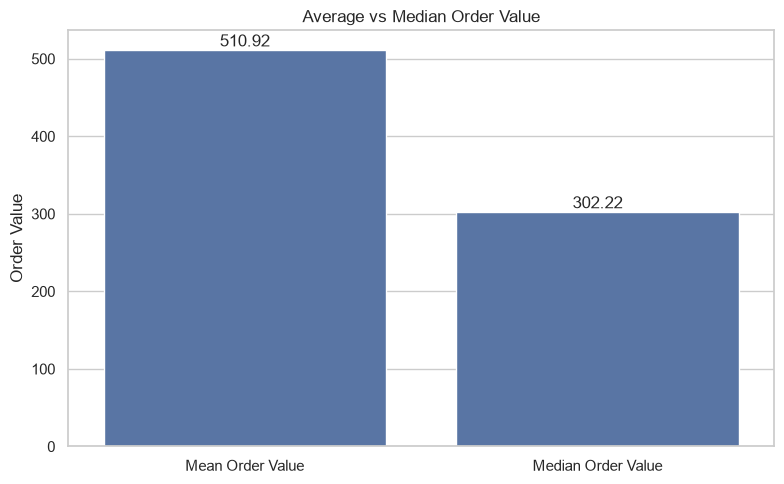

In [182]:
# Compare the mean and median invoice values.
plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Mean Order Value", "Median Order Value"],
    y=[510.92, 302.22]
)

plt.title("Average vs Median Order Value")
plt.ylabel("Order Value")
plt.xlabel("")

# Add value labels above the bars.
for i, value in enumerate([510.92, 302.22]):
    plt.text(i, value + 5, f"{value:.2f}", ha="center")

plt.tight_layout()
plt.savefig(
    images_dir / "Average_vs_Median_Order_Value.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [142]:
# Check the distribution of invoice counts per customer.
customer_orders.describe()

count    5878.000000
mean        6.289384
std        13.009406
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       398.000000
Name: Invoice, dtype: float64

In [143]:
# Check the number of rows without a Customer ID.
sales["Customer ID"].isna().sum()

np.int64(228489)

In [144]:
# Keep rows with a known Customer ID and calculate sales revenue per customer.
customer_revenue = (
    sales.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Revenue"]
    .sum()
)
# Verify the result.
customer_revenue.head(10)

Customer ID
12346.0    77556.46
12347.0     4921.53
12348.0     2019.40
12349.0     4428.69
12350.0      334.40
12351.0      300.93
12352.0     2849.84
12353.0      406.76
12354.0     1079.40
12355.0      947.61
Name: Revenue, dtype: float64

In [145]:
# Combine invoice counts and sales revenue for each customer.
customer_summary = pd.DataFrame({
    "Number_of_Orders": customer_orders,
    "Net_Revenue": customer_revenue
})

# Top 10
customer_summary.head(10)

,Number_of_Orders,Net_Revenue
Customer ID,,
12346.0,12,77556.46
12347.0,8,4921.53
12348.0,5,2019.40
12349.0,4,4428.69
12350.0,1,334.40
12351.0,1,300.93
12352.0,10,2849.84
12353.0,2,406.76
12354.0,1,1079.40


## One-Time and Repeat Buyers

Customers are grouped by distinct invoice count: one-time buyers have one invoice, while repeat buyers have two or more. Revenue and revenue share are calculated from positive-sales rows for customers with recorded IDs. The shares compare these two customer groups and exclude transactions without a Customer ID and non-positive sales.

In [146]:
# Split customers into two groups.

customer_summary["Customer_Type"] = customer_summary[
    "Number_of_Orders"
].apply(
    lambda x: "Repeat Buyers" if x >= 2 else "One-time Buyers"
)
# Compare the customer groups.
buyer_analysis = customer_summary.groupby("Customer_Type").agg(
    Number_of_Customers=("Net_Revenue", "count"),
    Net_Revenue=("Net_Revenue", "sum"),
    Average_Revenue_per_Customer=("Net_Revenue", "mean")
)

# Calculate each group's share of revenue.
buyer_analysis["Revenue_Share_%"] = (
    buyer_analysis["Net_Revenue"]
    / buyer_analysis["Net_Revenue"].sum()
    * 100
)

buyer_analysis.round(2)

,Number_of_Customers,Net_Revenue,Average_Revenue_per_Customer,Revenue_Share_%
Customer_Type,,,,
One-time Buyers,1623,560272.56,345.21,3.22
Repeat Buyers,4255,16814531.71,3951.71,96.78


The charts compare the customer counts and shares of sales revenue for one-time and repeat buyers. Revenue shares include only customers with recorded IDs in the positive-sales subset.

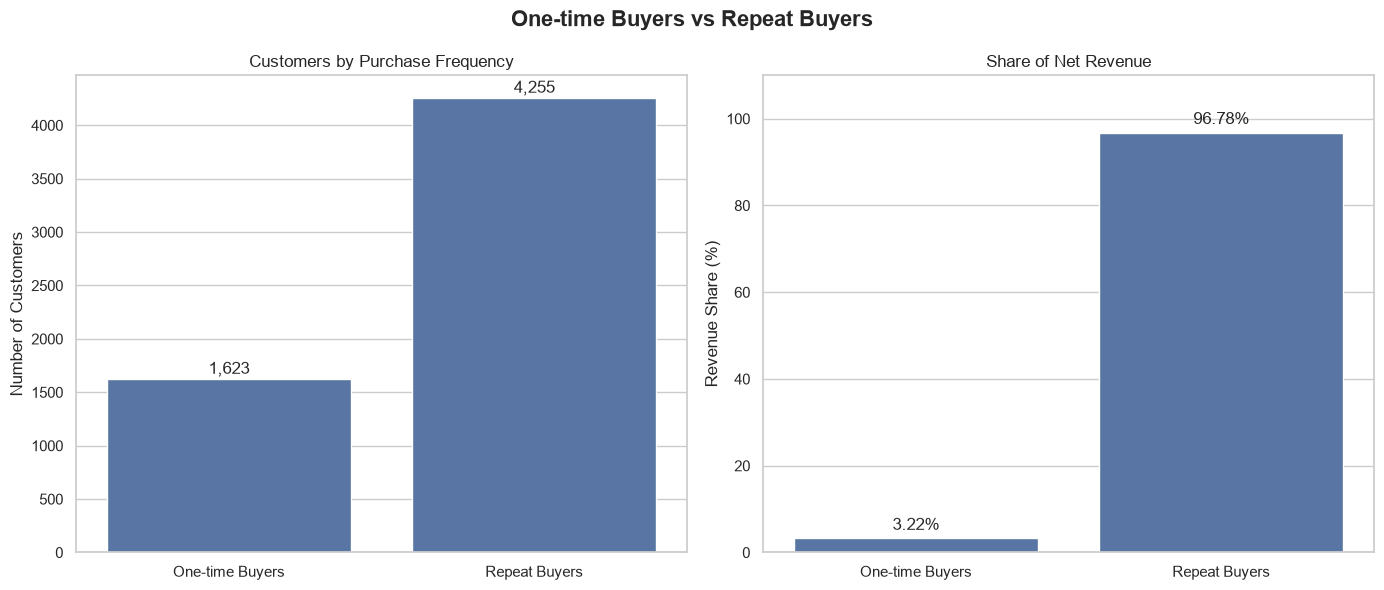

In [183]:

# Compare one-time and repeat buyers.

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: number of customers.
customer_counts = buyer_analysis["Number_of_Customers"]

sns.barplot(
    x=customer_counts.index,
    y=customer_counts.values,
    ax=axes[0]
)

axes[0].set_title("Customers by Purchase Frequency")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of Customers")

for i, value in enumerate(customer_counts.values):
    axes[0].text(i, value + 50, f"{value:,}", ha="center")

# Chart 2: share of sales revenue.
revenue_shares = buyer_analysis["Revenue_Share_%"]

sns.barplot(
    x=revenue_shares.index,
    y=revenue_shares.values,
    ax=axes[1]
)

axes[1].set_title("Share of Net Revenue")
axes[1].set_xlabel("")
axes[1].set_ylabel("Revenue Share (%)")
axes[1].set_ylim(0, 110)

for i, value in enumerate(revenue_shares.values):
    axes[1].text(i, value + 2, f"{value:.2f}%", ha="center")

plt.suptitle(
    "One-time Buyers vs Repeat Buyers",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    images_dir / "1_time_vs_x_time_buyers.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## Time Between First and Second Invoices

This analysis finds the first and second distinct invoices for each customer with a recorded Customer ID, using positive-sales rows. Customers with fewer than two invoices have no second invoice date and are excluded from the time-between-invoices calculation.

In [148]:
sales["InvoiceDate"].dtype

dtype('<M8[us]')

In [149]:
# First Order
first_order = (
    sales.groupby("Customer ID")["InvoiceDate"]
    .min()
)

first_order.head(10)

Customer ID
12346.0   2009-12-14 08:34:00
12347.0   2010-10-31 14:20:00
12348.0   2010-09-27 14:59:00
12349.0   2010-04-29 13:20:00
12350.0   2011-02-02 16:01:00
12351.0   2010-11-29 15:23:00
12352.0   2010-11-12 10:20:00
12353.0   2010-10-27 12:44:00
12354.0   2011-04-21 13:11:00
12355.0   2010-05-21 11:59:00
Name: InvoiceDate, dtype: datetime64[us]

In [150]:
# SEcond Order
second_order = (
    sales.groupby("Customer ID")["InvoiceDate"]
    .apply(lambda dates: dates.drop_duplicates().sort_values().iloc[1]
           if dates.nunique() >= 2 else pd.NaT)
)

second_order.head(10)

Customer ID
12346.0   2009-12-14 11:00:00
12347.0   2010-12-07 14:57:00
12348.0   2010-12-16 19:09:00
12349.0   2010-05-18 09:57:00
12350.0                   NaT
12351.0                   NaT
12352.0   2010-11-29 10:07:00
12353.0   2011-05-19 17:47:00
12354.0                   NaT
12355.0   2011-05-09 13:49:00
Name: InvoiceDate, dtype: datetime64[us]

In [151]:
# Calculate the number of days between the first and second invoices.
days_to_repeat = (
    (second_order - first_order)
    .dt.total_seconds() / (24 * 60 * 60)
)

days_to_repeat.head(10)

Customer ID
12346.0      0.101389
12347.0     37.025694
12348.0     80.173611
12349.0     18.859028
12350.0           NaN
12351.0           NaN
12352.0     16.990972
12353.0    204.210417
12354.0           NaN
12355.0    353.076389
Name: InvoiceDate, dtype: float64

In [152]:
# Review the distribution of time to the second invoice.

days_to_repeat.describe().round(2)

count    4256.00
mean       97.37
std       112.73
min         0.00
25%        20.87
50%        55.95
75%       130.39
max       714.15
Name: InvoiceDate, dtype: float64

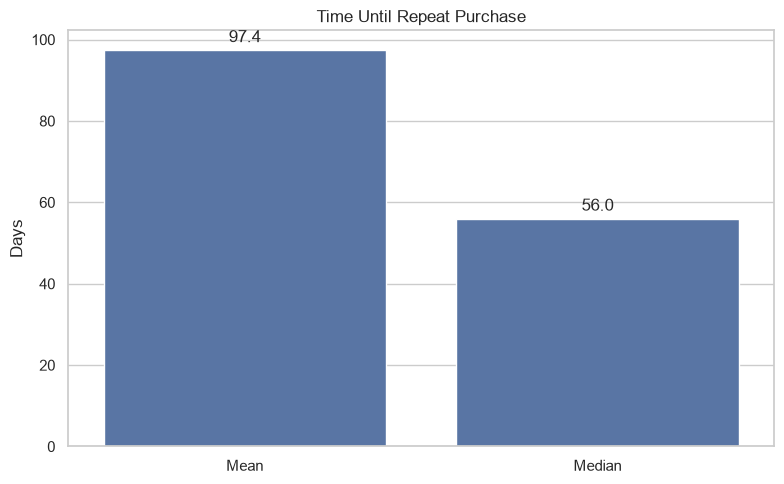

In [184]:
# Compare the mean and median time to the second invoice.
mean_days = days_to_repeat.mean()
median_days = days_to_repeat.median()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Mean", "Median"],
    y=[mean_days, median_days]
)

plt.title("Time Until Repeat Purchase")
plt.ylabel("Days")
plt.xlabel("")

for i, value in enumerate([mean_days, median_days]):
    plt.text(i, value + 2, f"{value:.1f}", ha="center")

plt.tight_layout()
plt.savefig(
    images_dir / "Time_Until_Repeat _Purchase.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## A separate folder containing the saved charts.

In [157]:
from pathlib import Path

images_dir = Path.cwd() / "images"
images_dir.mkdir(parents=True, exist_ok=True)

print(f"Images folder: {images_dir.resolve()}")

Images folder: D:\Python Lessons\OnlineRetailProject\notebooks\images


## Export the Cleaned Dataset

The cleaned transaction-level dataset is exported in two formats: CSV, JSON. Each file contains the same records and columns. Exact duplicate rows have been removed; returns and rows with missing customer IDs are retained.

In [156]:
from pathlib import Path
import pandas as pd

# Create an output folder in the current project directory.
output_dir = Path.cwd() / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Export the complete cleaned dataset, not the positive-sales-only subset.
export_df = df.copy()


export_df.to_csv(
    output_dir / "online_retail_cleaned.csv",
    index=False,
    encoding="utf-8",
    date_format="%Y-%m-%d %H:%M:%S"
)

export_df.to_json(
    output_dir / "online_retail_cleaned.json",
    orient="records",
    date_format="iso",
    force_ascii=False
)



print(f"Files saved to: {output_dir.resolve()}")

Files saved to: D:\Python Lessons\OnlineRetailProject\notebooks\outputs


## Data Preparation

The original dataset contained 1,067,371 rows. After removing 34,335 exact duplicate rows, 1,033,036 rows remained. Invoice dates were converted to datetime format, with no unparseable dates. Records with missing customer IDs and negative quantities were retained in the cleaned dataset; customer-level analysis was limited to records with an identified customer ID.

## Revenue Definitions

Gross sales revenue is calculated from transactions with positive quantities and prices. Net revenue includes the revenue values recorded across transactions, including negative-value entries such as returns or cancellations. Revenue is not the same as profit because product costs are not available in the dataset.

Product, country, and customer comparisons based on the `sales` subset describe positive sales only. They should not be interpreted as net revenue after returns.

## Key Findings

- Monthly sales revenue was strongest in November 2010 and November 2011. February 2010 and February 2011 were among the weakest months, with March 2011 also showing low sales. This pattern may reflect seasonal demand, but the data cannot establish the cause.
- The United Kingdom ranked first in both positive-sales revenue and unique invoice count. Rankings for other countries varied between the two measures, showing that revenue and invoice volume capture different aspects of market activity.
- Product rankings differed depending on whether products were compared by revenue or units sold. High unit volume did not always correspond to high revenue. Unusually large quantities and cancellation pairs can also affect unit-based rankings.
- Among customers with an identified Customer ID, repeat buyers accounted for 72.39% of customers and 96.78% of revenue in the positive-sales customer analysis.
- The average order value was 510.92, compared with a median of 302.22. The higher average suggests that some large orders raised the mean.
- For customers with at least two distinct invoices, the time between the first and second invoice was 97.52 days on average and 55.96 days at the median.

## Recommendations

- Explore ways to encourage one-time buyers to make a second purchase.
- Use the November peaks and February lows as planning signals, and compare them with additional years of data before making seasonal decisions.
- Review unusually large quantity transactions and related cancellations before using unit rankings to guide business decisions.
- Compare countries using both revenue and unique invoice counts. Consider order value as an additional measure when assessing markets.
- Evaluate product performance using both revenue and units sold rather than relying on only one ranking.

## Limitations

- Customer-level findings exclude transactions without a Customer ID.
- Customer and product comparisons based on `sales` use positive-quantity, positive-price transactions; they do not represent net revenue after returns.
- Negative quantities and other unusual transaction values may represent returns, cancellations, or adjustments, but their exact business meaning is not always clear.
- The dataset covers December 2009 to December 2011, with incomplete months at the beginning and end of the period. The observed monthly pattern is not enough to prove a recurring seasonal effect.
- Revenue does not account for product costs, so it cannot be used to calculate profit.